# MIT Academy of Engineering, Alandi (D), Pune
### Department of Computer Engineering — TY BTech (Semester V, AY 2025–2026)

**Course:** `2304322T` — Artificial Intelligence and Machine Learning  
**Assignment No.:** 2 (`ACAD/DI/11A`, Rev. 01)  
**Problem Statement (PS):** *To implement techniques of Feature Engineering to transform raw data into informative features.*  
**Bloom's Taxonomy (RBT) Level:** Level 3 (Applying) | **Course Outcome:** CO2 | **Maximum Marks:** 10

---

## Rubric & Program Outcome (PO) Alignment Matrix

| Rubric Criterion | CO | POs | Target Engineering Evidence in This Notebook | Max Marks |
| :--- | :---: | :---: | :--- | :---: |
| **1. Statistical Concepts & Mathematical Intuition** | CO2 | PO1 | Formal derivations & tests for skewness ($\gamma_1$), kurtosis ($\gamma_2$), Shapiro–Wilk normality, MCAR/MAR/MNAR diagnosis, Box–Cox/Yeo–Johnson, $m$-smoothed target encoding, VIF ($\frac{1}{1-R_j^2}$), Mutual Information $I(X;Y)$, PCA eigendecomposition, and paired $t$/Wilcoxon significance tests. | **2.5** |
| **2. Problem Analysis & Feature Engineering** | CO2 | PO2, PO3 | Real-world Ames Housing audit (1,460 × 80): semantic type correction (`MSSubClass`), domain-aware structural missingness handling, outlier leverage diagnostics (Cook's $D_i$), cyclical temporal encoding, interaction ratios, and multi-paradigm feature selection (Filter + Wrapper RFECV + Embedded $L_1$/Permutation). | **2.5** |
| **3. Data Preparation & Feature Engineering** | CO2 | PO4 | Zero-leakage `train_test_split` prior to fitting; modular `BaseEstimator`/`TransformerMixin` `scikit-learn` `Pipeline` & `ColumnTransformer`; imputation strategy benchmarking; and a rigorous 5-stage progressive ablation study across 4 model families. | **2.5** |
| **4. Presentation & Data Visualization** | CO2 | PO5, PO12 | Publication-grade 300 DPI multi-panel figures (missingness anatomy, Q-Q normality, Cook's distance, scaling sensitivity, pipeline architecture, VIF/correlation, selection convergence, PCA scree, ablation & residual diagnostics) with reproducible MLOps engineering standards. | **2.5** |

In [1]:
import os
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from scipy import stats
from scipy.stats import shapiro, normaltest, ttest_rel, wilcoxon

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    PowerTransformer,
    QuantileTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder,
    KBinsDiscretizer,
    PolynomialFeatures,
)
from sklearn.feature_selection import (
    mutual_info_regression,
    f_regression,
    RFECV,
    SelectFromModel,
)
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, RidgeCV, LassoCV, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Reproducibility & Output Directories
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("data", exist_ok=True)

# Publication-grade Matplotlib Styling
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
sns.set_theme(style="whitegrid", palette="colorblind")
PALETTE = sns.color_palette("colorblind")

# Load Ames Housing Dataset (Local cache if available, else OpenML for Google Colab)
LOCAL_CSV = os.path.join("data", "ames_housing.csv")
if os.path.exists(LOCAL_CSV):
    df_raw = pd.read_csv(LOCAL_CSV)
    data_source = f"Local cached CSV ({LOCAL_CSV})"
else:
    housing = fetch_openml(name="house_prices", as_frame=True, parser="auto")
    df_raw = housing.frame
    df_raw.to_csv(LOCAL_CSV, index=False)
    data_source = "OpenML ('house_prices')"

print(f"Data loaded from: {data_source}")
print(f"Dataset shape: {df_raw.shape[0]} observations x {df_raw.shape[1]} columns")
df_raw.head(3)

Data loaded from: Local cached CSV (data\ames_housing.csv)
Dataset shape: 1460 observations x 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


---
## 1. Problem Analysis & Semantic Data Audit (PO1, PO2)

### 1.1 Problem Formulation
We address **Residential Real Estate Valuation** using the **Ames Housing Dataset** (De Cock, 2011), comprising $N = 1,460$ residential property transactions across $p = 80$ raw attributes and a continuous monetary target $y = \text{SalePrice}$ (USD). Unlike clean toy datasets, Ames Housing exhibits virtually every real-world feature engineering challenge:
1. **Mixed Feature Modalities:** 17 continuous measurements, 18 discrete counts/years, 15 ordered quality/condition scales, and 28 nominal categories (including high-cardinality `Neighborhood` with 25 levels).
2. **Type Misrepresentation:** `MSSubClass` (Dwelling Type Code, e.g., `20 = 1-STORY 1946+`, `60 = 2-STORY 1946+`) is encoded as `int64`, creating false linear ordering if left numeric.
3. **Identifier Leakage Risk:** `Id` is a monotonically assigned surrogate index and must be dropped prior to modeling.
4. **Heterogeneous Missingness Mechanisms (Rubin's Taxonomy):**
   - **MNAR (Structural Absence):** 14 amenity features (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*`, `MasVnrType`) are `NaN` precisely when the physical structure does *not* exist on the property. Replacing these with mode/median destroys structural signal; domain-aware `"None"` / `0` encoding + binary presence flags preserves it.
   - **MAR (Missing at Random):** `LotFrontage` (linear feet of street connected to property) is missing in $259/1460$ ($17.74\%$) records, conditioned systematically on `Neighborhood` and `LotConfig`.
   - **MCAR (Missing Completely at Random):** `Electrical` has $1/1460$ ($0.07\%$) isolated missing record.

MSSubClass dtype in raw CSV: int64, unique codes: [np.int64(20), np.int64(30), np.int64(40), np.int64(45), np.int64(50), np.int64(60), np.int64(70), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(120), np.int64(160), np.int64(180), np.int64(190)]

=== Missing Data Anatomy (19 Columns) ===


,Missing_Count,Missing_Pct,Mechanism
PoolQC,1453,99.520548,MNAR (Structural Absence)
MiscFeature,1406,96.301370,MNAR (Structural Absence)
Alley,1369,93.767123,MNAR (Structural Absence)
Fence,1179,80.753425,MNAR (Structural Absence)
MasVnrType,872,59.726027,MNAR (Structural Absence)
FireplaceQu,690,47.260274,MNAR (Structural Absence)
LotFrontage,259,17.739726,MAR (Neighborhood-Dependent)
GarageType,81,5.547945,MNAR (Structural Absence)
GarageYrBlt,81,5.547945,MNAR (Structural Absence)
GarageFinish,81,5.547945,MNAR (Structural Absence)



One-Way ANOVA (LotFrontage ~ Neighborhood): F = 14.55, p = 1.741e-49
-> Strong rejection of H0 (p << 0.001): LotFrontage depends significantly on Neighborhood (MAR confirmed).


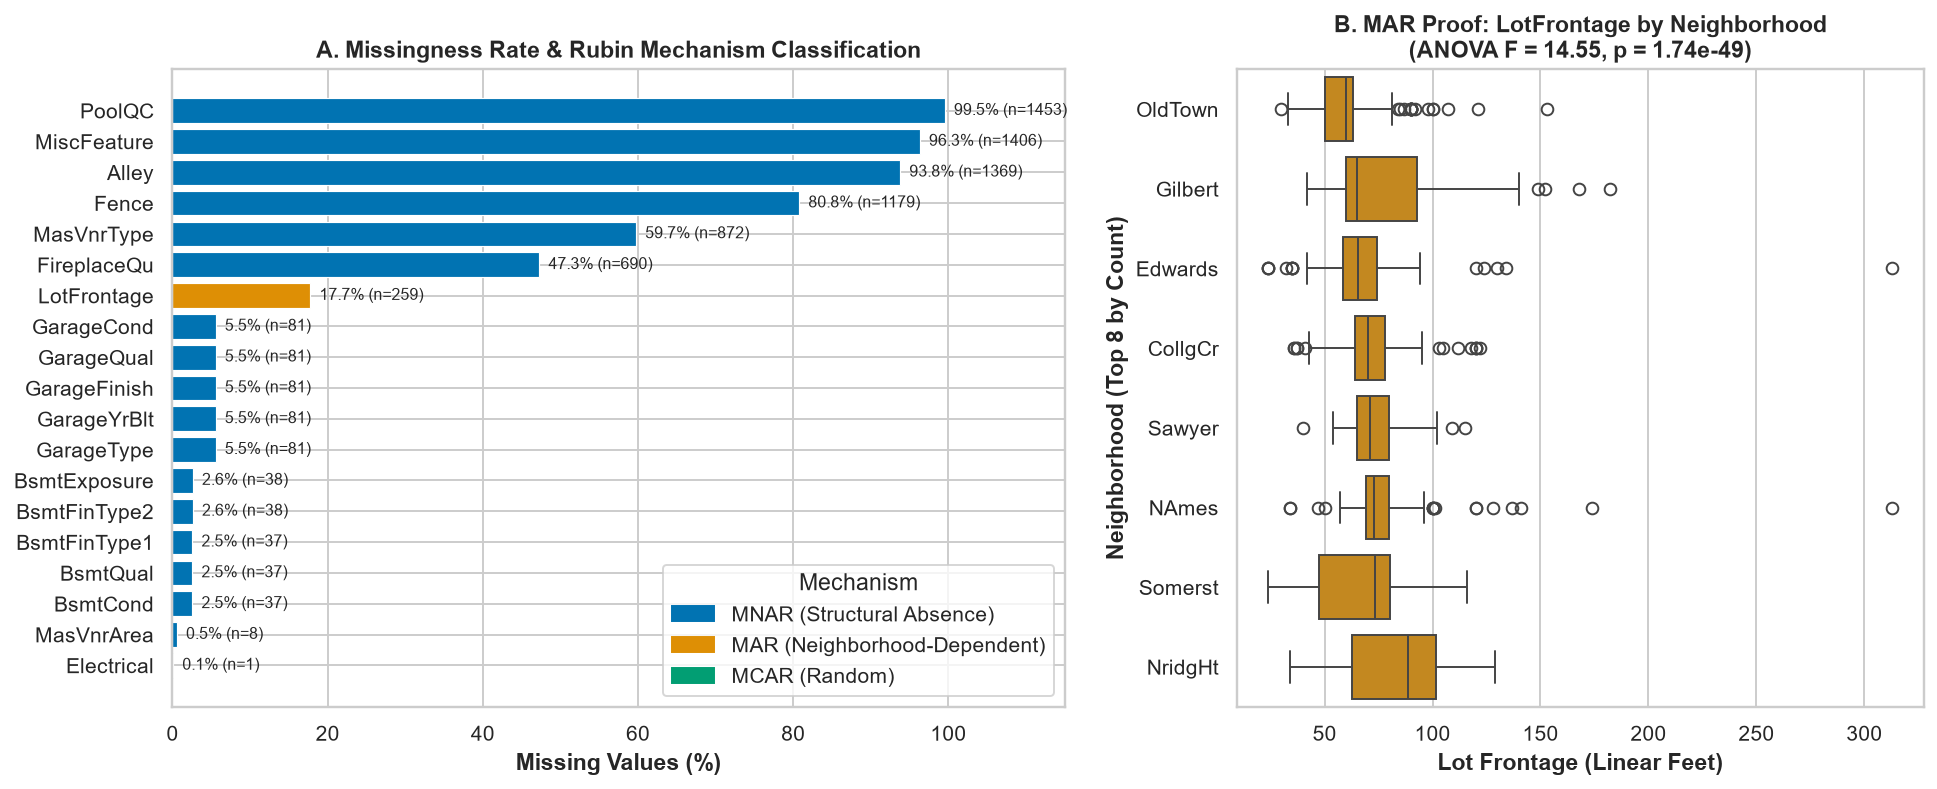

In [2]:
# 1. Semantic Schema Audit & Missingness Mechanism Analysis
df_audit = df_raw.copy()

# Check MSSubClass numeric misconception
print(f"MSSubClass dtype in raw CSV: {df_audit['MSSubClass'].dtype}, unique codes: {sorted(df_audit['MSSubClass'].unique())}")

# Quantify missingness
missing_counts = df_audit.isnull().sum()
missing_df = pd.DataFrame({
    "Missing_Count": missing_counts[missing_counts > 0],
    "Missing_Pct": (missing_counts[missing_counts > 0] / len(df_audit)) * 100,
}).sort_values("Missing_Pct", ascending=False)

mnar_structural = {
    "PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "MasVnrArea",
    "FireplaceQu", "GarageType", "GarageYrBlt", "GarageFinish", "GarageQual",
    "GarageCond", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"
}
missing_df["Mechanism"] = [
    "MNAR (Structural Absence)" if col in mnar_structural
    else ("MAR (Neighborhood-Dependent)" if col == "LotFrontage" else "MCAR (Random)")
    for col in missing_df.index
]
print("\n=== Missing Data Anatomy (19 Columns) ===")
display(missing_df)

# Statistical Hypothesis Test for MAR on LotFrontage across Neighborhoods (One-Way ANOVA)
groups = [g["LotFrontage"].dropna().values for _, g in df_audit.groupby("Neighborhood") if len(g["LotFrontage"].dropna()) >= 5]
f_stat, p_val_mar = stats.f_oneway(*groups)
print(f"\nOne-Way ANOVA (LotFrontage ~ Neighborhood): F = {f_stat:.2f}, p = {p_val_mar:.3e}")
print("-> Strong rejection of H0 (p << 0.001): LotFrontage depends significantly on Neighborhood (MAR confirmed).")

# FIGURE 1: Missing Data Anatomy & Mechanism Classification
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.3, 1]})

mech_colors = {
    "MNAR (Structural Absence)": PALETTE[0],
    "MAR (Neighborhood-Dependent)": PALETTE[1],
    "MCAR (Random)": PALETTE[2],
}
plot_m = missing_df.sort_values("Missing_Pct", ascending=True)
colors = [mech_colors[m] for m in plot_m["Mechanism"]]

bars = axes[0].barh(plot_m.index, plot_m["Missing_Pct"], color=colors, edgecolor="white", linewidth=0.6)
axes[0].set_title("A. Missingness Rate & Rubin Mechanism Classification")
axes[0].set_xlabel("Missing Values (%)")
axes[0].set_xlim(0, 115)
for bar, pct, cnt in zip(bars, plot_m["Missing_Pct"], plot_m["Missing_Count"]):
    axes[0].text(bar.get_width() + 1.2, bar.get_y() + bar.get_height()/2,
                 f"{pct:.1f}% (n={cnt})", va="center", fontsize=8)

legend_handles = [mpatches.Patch(color=c, label=lbl) for lbl, c in mech_colors.items()]
axes[0].legend(handles=legend_handles, loc="lower right", frameon=True, title="Mechanism")

# Panel B: LotFrontage Variation by Top-8 Neighborhoods (Visualizing MAR)
top_neigh = df_audit["Neighborhood"].value_counts().head(8).index
sub_neigh = df_audit[df_audit["Neighborhood"].isin(top_neigh)].copy()
order_n = sub_neigh.groupby("Neighborhood")["LotFrontage"].median().sort_values().index
sns.boxplot(data=sub_neigh, y="Neighborhood", x="LotFrontage", order=order_n, ax=axes[1], color=PALETTE[1])
axes[1].set_title(f"B. MAR Proof: LotFrontage by Neighborhood\n(ANOVA F = {f_stat:.2f}, p = {p_val_mar:.2e})")
axes[1].set_xlabel("Lot Frontage (Linear Feet)")
axes[1].set_ylabel("Neighborhood (Top 8 by Count)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_missingness_anatomy.png"), dpi=300, bbox_inches="tight")
plt.show()

---
## 2. Statistical Concepts, Distributional Transformations & Outlier Diagnostics (PO1, PO4)

### 2.1 Mathematical Intuition of Distributional Asymmetry & Normality
Linear models and distance-based learners rely on symmetric, homoscedastic error structures. We quantify departure from Gaussianity via sample **Skewness** ($\gamma_1$) and **Excess Kurtosis** ($\gamma_2$):
$$\gamma_1 = \frac{\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^3}{\left(\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2\right)^{3/2}}, \qquad \gamma_2 = \frac{\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^4}{\left(\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2\right)^2} - 3$$
We formally test Gaussianity with the **Shapiro–Wilk test** ($W \in (0, 1]$, rejecting $H_0$: normality when $p < 0.05$).

### 2.2 Power & Rank Transformations
1. **Log1p Transformation:** $T_{\log}(x) = \ln(1 + x)$ for non-negative right-skewed financial/area targets (`SalePrice`, `LotArea`), compressing multiplicative variance into additive scale.
2. **Yeo–Johnson Transformation:** Extends Box–Cox to $x \le 0$ using a maximum-likelihood parameter $\lambda$ estimated strictly on training folds:
$$\psi(\lambda, x) = \begin{cases} \frac{(x+1)^\lambda - 1}{\lambda}, & \lambda \neq 0, x \ge 0 \\ \ln(x+1), & \lambda = 0, x \ge 0 \\ -\frac{(-x+1)^{2-\lambda} - 1}{2-\lambda}, & \lambda \neq 2, x < 0 \\ -\ln(-x+1), & \lambda = 2, x < 0 \end{cases}$$
3. **Quantile Transformation (Gaussian Output):** Non-parametric mapping $T_Q(x) = \Phi^{-1}(\hat{F}_X(x))$ via empirical CDF $\hat{F}_X$ and standard normal inverse CDF $\Phi^{-1}$.

### 2.3 Robust Outlier & Influence Diagnostics
Because standard $Z$-scores ($z_i = \frac{x_i - \mu}{\sigma}$) are corrupted by the very outliers they attempt to detect, we combine three complementary criteria on `X_train` only:
- **Tukey IQR Fences:** $[Q_1 - 1.5\cdot\text{IQR},\; Q_3 + 1.5\cdot\text{IQR}]$
- **Modified $Z$-Score (MAD):** $M_i = \frac{0.6745(x_i - \tilde{x})}{\text{median}(|x_j - \tilde{x}|)}$, flagging $|M_i| > 3.5$
- **Cook's Distance (Regression Leverage):** $D_i = \frac{e_i^2}{p \cdot \text{MSE}} \cdot \frac{h_{ii}}{(1 - h_{ii})^2}$, flagging influential points exceeding $D_i > \frac{4}{n}$.

> **Data-Leakage Discipline:** Before fitting any transformation, imputation, outlier bound, or encoder, we execute an 80/20 `train_test_split` (`random_state=42`). Test observations remain strictly unseen until final evaluation.

Train split: (1168, 79), Test split: (292, 79) (strictly held out)

Target SalePrice (Train) — Raw: skew=1.743, kurt=5.475, Shapiro W=0.8811 (p=5.50e-29)
Target SalePrice (Train) — Log1p: skew=0.125, kurt=0.700, Shapiro W=0.9925 (p=1.15e-05)

=== Skewness Reduction Across Transformations (Fit on X_train Only) ===


,Feature,Raw_Skew,Log1p_Skew,YeoJohnson_Skew,YJ_Lambda,QuantileNorm_Skew
0,LotArea,11.9581,-0.0126,0.0024,0.0027,0.0045
1,GrLivArea,1.4251,0.0079,-0.0003,-0.0071,-0.0014
2,MasVnrArea,2.2941,0.4526,0.3793,-0.2188,0.3856
3,TotalBsmtSF,1.7239,-5.2746,0.2867,0.7295,-1.4066
4,OpenPorchSF,2.3319,-0.0641,-0.0396,0.0313,-0.1608


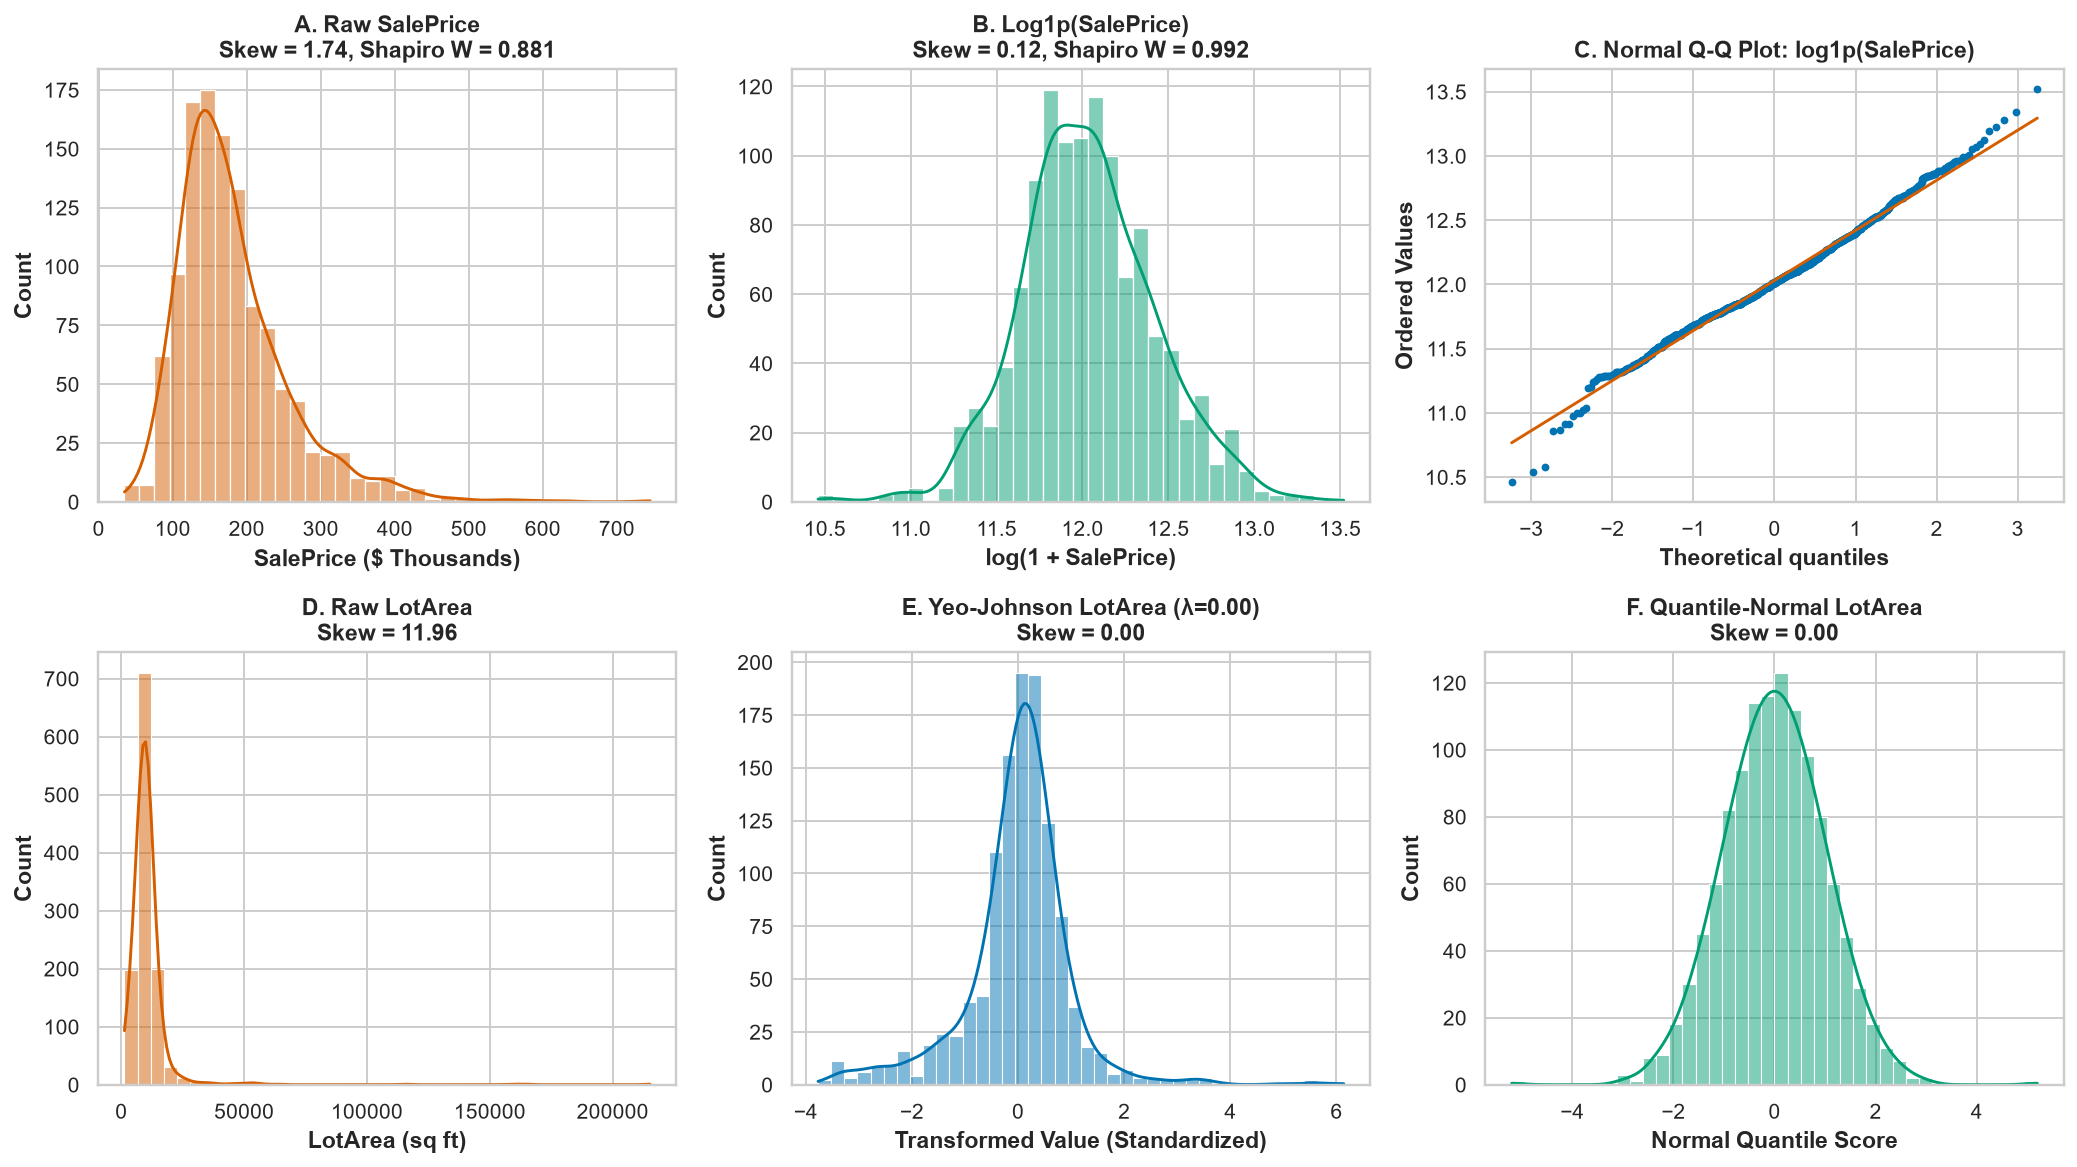

In [3]:
# Strict Train / Test Split BEFORE any distributional parameter estimation
df_clean_base = df_raw.drop(columns=["Id"]).copy()
df_clean_base["MSSubClass"] = df_clean_base["MSSubClass"].astype(str)

X_full = df_clean_base.drop(columns=["SalePrice"])
y_full = df_clean_base["SalePrice"].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train split: {X_train.shape}, Test split: {X_test.shape} (strictly held out)")

# Target Variable Distributional Analysis
y_train_log = np.log1p(y_train)
w_raw, p_raw = shapiro(y_train)
w_log, p_log = shapiro(y_train_log)
print(f"\nTarget SalePrice (Train) — Raw: skew={y_train.skew():.3f}, kurt={y_train.kurt():.3f}, Shapiro W={w_raw:.4f} (p={p_raw:.2e})")
print(f"Target SalePrice (Train) — Log1p: skew={y_train_log.skew():.3f}, kurt={y_train_log.kurt():.3f}, Shapiro W={w_log:.4f} (p={p_log:.2e})")

# Compare Power Transformations across Top Skewed Numeric Features (Fit on Train Only!)
skewed_candidates = ["LotArea", "GrLivArea", "MasVnrArea", "TotalBsmtSF", "OpenPorchSF"]
trans_rows = []
for col in skewed_candidates:
    s_tr = X_train[col].fillna(0).values.reshape(-1, 1)
    s_log = np.log1p(np.clip(s_tr, 0, None))
    pt = PowerTransformer(method="yeo-johnson", standardize=False)
    s_yj = pt.fit_transform(s_tr)
    qt = QuantileTransformer(n_quantiles=min(500, len(s_tr)), output_distribution="normal", random_state=RANDOM_STATE)
    s_qt = qt.fit_transform(s_tr)
    trans_rows.append({
        "Feature": col,
        "Raw_Skew": float(pd.Series(s_tr.ravel()).skew()),
        "Log1p_Skew": float(pd.Series(s_log.ravel()).skew()),
        "YeoJohnson_Skew": float(pd.Series(s_yj.ravel()).skew()),
        "YJ_Lambda": float(pt.lambdas_[0]),
        "QuantileNorm_Skew": float(pd.Series(s_qt.ravel()).skew()),
    })

trans_df = pd.DataFrame(trans_rows)
print("\n=== Skewness Reduction Across Transformations (Fit on X_train Only) ===")
display(trans_df.round(4))

# FIGURE 2: Target & Feature Distributional Diagnostics (Hist+KDE & Q-Q Plots)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))

# Row 1: SalePrice Raw vs Log1p + Q-Q
sns.histplot(y_train / 1000, kde=True, ax=axes[0, 0], color=PALETTE[3], bins=35)
axes[0, 0].set_title(f"A. Raw SalePrice\nSkew = {y_train.skew():.2f}, Shapiro W = {w_raw:.3f}")
axes[0, 0].set_xlabel("SalePrice ($ Thousands)")

sns.histplot(y_train_log, kde=True, ax=axes[0, 1], color=PALETTE[2], bins=35)
axes[0, 1].set_title(f"B. Log1p(SalePrice)\nSkew = {y_train_log.skew():.2f}, Shapiro W = {w_log:.3f}")
axes[0, 1].set_xlabel("log(1 + SalePrice)")

stats.probplot(y_train_log, dist="norm", plot=axes[0, 2])
axes[0, 2].get_lines()[0].set_color(PALETTE[0])
axes[0, 2].get_lines()[0].set_markersize(3)
axes[0, 2].get_lines()[1].set_color(PALETTE[3])
axes[0, 2].set_title("C. Normal Q-Q Plot: log1p(SalePrice)")

# Row 2: LotArea Raw vs Yeo-Johnson vs QuantileNormal
lot_raw = X_train["LotArea"].values.reshape(-1, 1)
pt_lot = PowerTransformer(method="yeo-johnson", standardize=True)
lot_yj = pt_lot.fit_transform(lot_raw).ravel()
qt_lot = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=RANDOM_STATE)
lot_qt = qt_lot.fit_transform(lot_raw).ravel()

sns.histplot(lot_raw.ravel(), kde=True, ax=axes[1, 0], color=PALETTE[3], bins=40)
axes[1, 0].set_title(f"D. Raw LotArea\nSkew = {pd.Series(lot_raw.ravel()).skew():.2f}")
axes[1, 0].set_xlabel("LotArea (sq ft)")

sns.histplot(lot_yj, kde=True, ax=axes[1, 1], color=PALETTE[0], bins=40)
axes[1, 1].set_title(f"E. Yeo-Johnson LotArea (λ={pt_lot.lambdas_[0]:.2f})\nSkew = {pd.Series(lot_yj).skew():.2f}")
axes[1, 1].set_xlabel("Transformed Value (Standardized)")

sns.histplot(lot_qt, kde=True, ax=axes[1, 2], color=PALETTE[2], bins=40)
axes[1, 2].set_title(f"F. Quantile-Normal LotArea\nSkew = {pd.Series(lot_qt).skew():.2f}")
axes[1, 2].set_xlabel("Normal Quantile Score")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_distributional_transforms.png"), dpi=300, bbox_inches="tight")
plt.show()

IQR upper fence for GrLivArea: 2761.4 sq ft (23 train records above fence)
Modified Z-score > 3.5 count: 13 train records
Cook's Distance threshold (4/n = 0.00342): 59 influential points
Extreme High-Area / Low-Price Anomalies (GrLivArea > 4000 & SalePrice < $300k): 2 records


,GrLivArea,SalePrice,SaleCondition,Mod_Z_Score,Cooks_D
523,4676,184750.0,Partial,6.70939,0.624444
1298,5642,160000.0,Partial,8.73289,7.337551


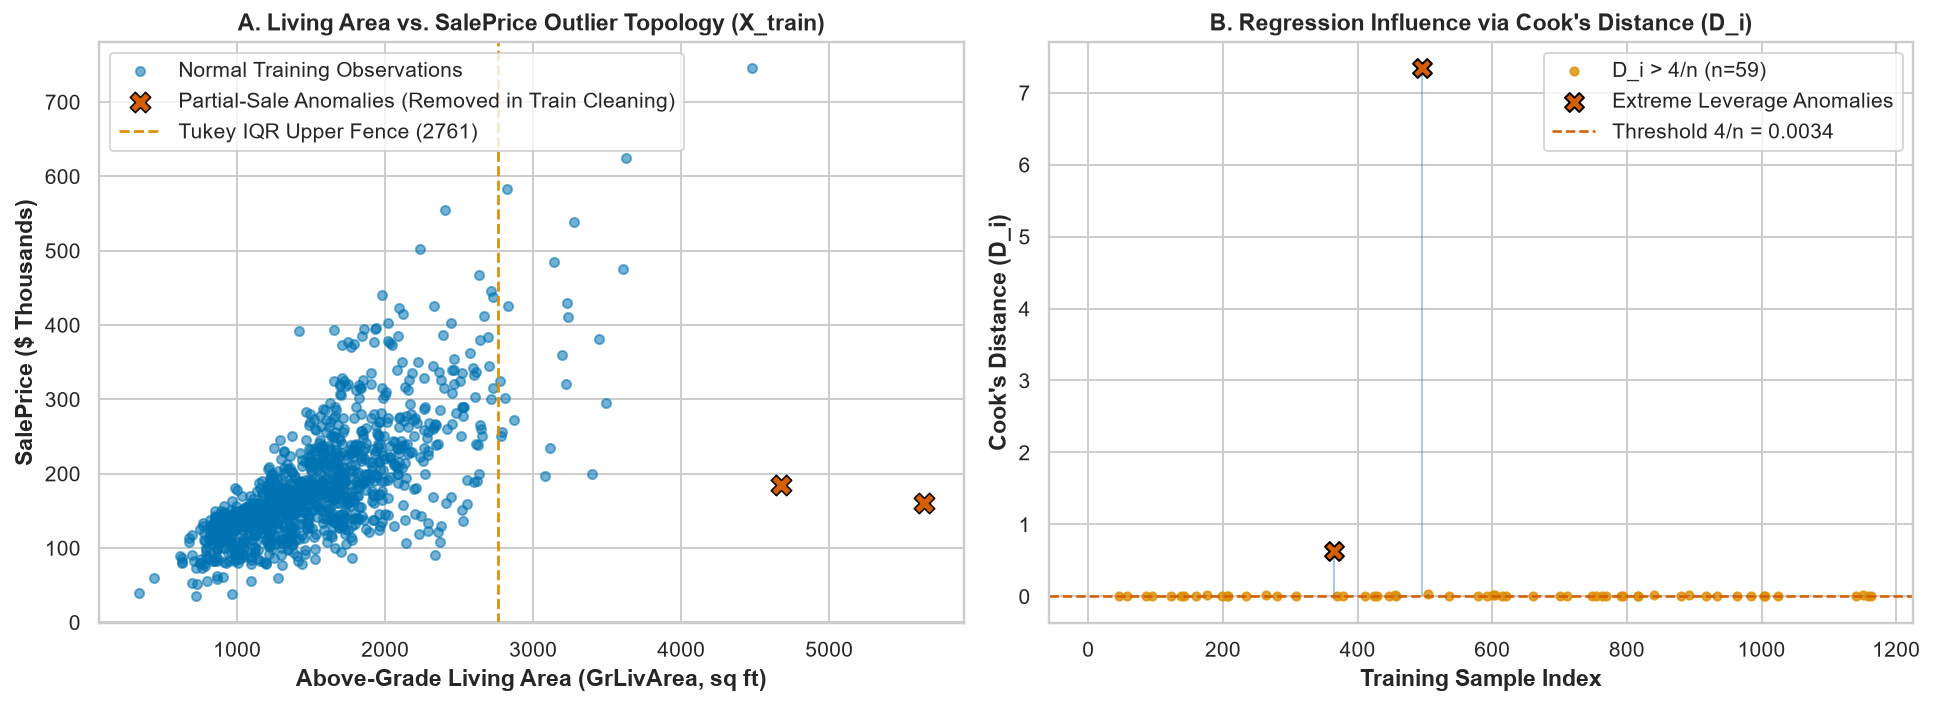

In [4]:
# Outlier & Influence Diagnostics on X_train Only
# Modified Z-score on GrLivArea
gr = X_train["GrLivArea"].values
med_gr = np.median(gr)
mad_gr = np.median(np.abs(gr - med_gr))
mod_z_gr = 0.6745 * (gr - med_gr) / mad_gr

# Tukey IQR Fences on GrLivArea
q1, q3 = np.percentile(gr, [25, 75])
iqr_gr = q3 - q1
upper_iqr_gr = q3 + 1.5 * iqr_gr

# OLS Cook's Distance (log1p(SalePrice) ~ GrLivArea + OverallQual + TotalBsmtSF)
ols_df = pd.DataFrame({
    "GrLivArea": X_train["GrLivArea"],
    "OverallQual": X_train["OverallQual"],
    "TotalBsmtSF": X_train["TotalBsmtSF"].fillna(0),
})
X_ols = sm.add_constant(ols_df)
ols_model = sm.OLS(y_train_log, X_ols).fit()
cooks_d = ols_model.get_influence().cooks_distance[0]
cooks_thresh = 4.0 / len(X_train)

# Identify extreme high-leverage anomalies (GrLivArea > 4000 & SalePrice < 300000)
anomalies_mask = (X_train["GrLivArea"] > 4000) & (y_train < 300000)
print(f"IQR upper fence for GrLivArea: {upper_iqr_gr:.1f} sq ft ({(gr > upper_iqr_gr).sum()} train records above fence)")
print(f"Modified Z-score > 3.5 count: {(np.abs(mod_z_gr) > 3.5).sum()} train records")
print(f"Cook's Distance threshold (4/n = {cooks_thresh:.5f}): {(cooks_d > cooks_thresh).sum()} influential points")
print(f"Extreme High-Area / Low-Price Anomalies (GrLivArea > 4000 & SalePrice < $300k): {anomalies_mask.sum()} records")
display(pd.DataFrame({
    "GrLivArea": X_train.loc[anomalies_mask, "GrLivArea"],
    "SalePrice": y_train.loc[anomalies_mask],
    "SaleCondition": X_train.loc[anomalies_mask, "SaleCondition"],
    "Mod_Z_Score": mod_z_gr[anomalies_mask.values],
    "Cooks_D": cooks_d[anomalies_mask.values],
}))

# FIGURE 3: Outlier & Leverage Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

normal_pts = ~anomalies_mask.values
axes[0].scatter(X_train.loc[normal_pts, "GrLivArea"], y_train.loc[normal_pts] / 1000,
                alpha=0.55, s=22, color=PALETTE[0], label="Normal Training Observations")
axes[0].scatter(X_train.loc[anomalies_mask, "GrLivArea"], y_train.loc[anomalies_mask] / 1000,
                s=110, color=PALETTE[3], marker="X", edgecolor="black", linewidth=0.8,
                label="Partial-Sale Anomalies (Removed in Train Cleaning)")
axes[0].axvline(upper_iqr_gr, color=PALETTE[1], linestyle="--", linewidth=1.4, label=f"Tukey IQR Upper Fence ({upper_iqr_gr:.0f})")
axes[0].set_title("A. Living Area vs. SalePrice Outlier Topology (X_train)")
axes[0].set_xlabel("Above-Grade Living Area (GrLivArea, sq ft)")
axes[0].set_ylabel("SalePrice ($ Thousands)")
axes[0].legend(loc="upper left", frameon=True)

# Panel B: Cook's Distance Influence Plot
idx_seq = np.arange(len(cooks_d))
axes[1].vlines(idx_seq, 0, cooks_d, colors=PALETTE[0], alpha=0.45, linewidth=0.8)
high_inf = cooks_d > cooks_thresh
axes[1].scatter(idx_seq[high_inf], cooks_d[high_inf], color=PALETTE[1], s=18, alpha=0.8, label=f"D_i > 4/n (n={high_inf.sum()})")
axes[1].scatter(idx_seq[anomalies_mask.values], cooks_d[anomalies_mask.values],
                color=PALETTE[3], s=95, marker="X", edgecolor="black", zorder=5, label="Extreme Leverage Anomalies")
axes[1].axhline(cooks_thresh, color=PALETTE[3], linestyle="--", linewidth=1.3, label=f"Threshold 4/n = {cooks_thresh:.4f}")
axes[1].set_title("B. Regression Influence via Cook's Distance (D_i)")
axes[1].set_xlabel("Training Sample Index")
axes[1].set_ylabel("Cook's Distance (D_i)")
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_outlier_cooks_diagnostics.png"), dpi=300, bbox_inches="tight")
plt.show()

---
## 3. Data Preparation, Categorical Encoding & Feature Scaling (PO3, PO4)

### 3.1 Imputation Strategy Benchmark (MAR `LotFrontage`)
To select the optimal imputer for `LotFrontage` (MAR), we benchmark 4 methods inside 5-fold CV on `X_train`:
1. **Global Median Imputation:** Constant $\tilde{x}$ ignoring `Neighborhood` structure.
2. **Neighborhood Group Median:** Conditional median $\tilde{x}_g$ per `Neighborhood` (with global fallback for unseen categories).
3. **$k$-Nearest Neighbors Imputation (`KNNImputer`, $k=5$):** Distance-weighted average using Euclidean nan-aware distance $d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{w \sum_{k \in \mathcal{O}} (x_{ik} - x_{jk})^2}$.
4. **Iterative Imputation (MICE):** Chained regression models predicting `LotFrontage` iteratively from correlated lot features (`LotArea`, `LotConfig`, `1stFlrSF`, `BldgType`).

### 3.2 Categorical Encoding Mathematics
- **Ordinal Quality Scales (15 features):** Preserves monotonic engineering order (`None=0 < Po=1 < Fa=2 < TA=3 < Gd=4 < Ex=5`) instead of blowing up dimensionality with unordered one-hot columns.
- **One-Hot Encoding with Rare Grouping (`min_frequency=15`):** Prevents sparse overfitting on infrequent categories and avoids the dummy-variable trap ($k-1$ rank constraint for linear models).
- **Out-of-Fold Smoothed Target Encoding (`Neighborhood`, `Exterior1st`, `Exterior2nd`):** Maps high-cardinality categories to smoothed conditional target expectations with $m$-estimate shrinkage:
$$\hat{y}_c = \frac{n_c \bar{y}_c + m \bar{y}_{\text{global}}}{n_c + m}$$
Computed strictly **out-of-fold (`cv=5`)** inside `sklearn.preprocessing.TargetEncoder` to eliminate target leakage.

### 3.3 Feature Scaling Formulations
- **Standardization (Z-Score):** $x' = \frac{x - \mu}{\sigma}$ — centers at 0 with unit variance; ideal for Ridge/Lasso/PCA.
- **Min-Max Scaling:** $x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \in [0, 1]$ — preserves sparsity, but heavily compressed by single extreme outliers.
- **Robust Scaling:** $x' = \frac{x - Q_2}{Q_3 - Q_1}$ — invariant to extreme tail outliers; ideal before winsorization or distance metrics.

=== LotFrontage Imputation Benchmark (20% Holdout Mask on Train) ===


,Imputation Method,Masked RMSE (feet)
2,"KNNImputer (k=7, weighted)",22.422
3,IterativeImputer (MICE),23.230
1,Neighborhood Group Median,24.811
0,Global Median,27.309



=== Quantile Discretization (KBinsDiscretizer, n=5) of YearBuilt vs. SalePrice ===


,Era_Range,count,median,mean
YearBin,,,,
0.0,1872–1947,232,124450.0,135518.0
1.0,1947–1965,227,139000.0,143208.0
2.0,1965–1984,240,149625.0,158488.0
3.0,1984–2003,210,212000.0,224093.0
4.0,2003–2010,259,222000.0,242775.0


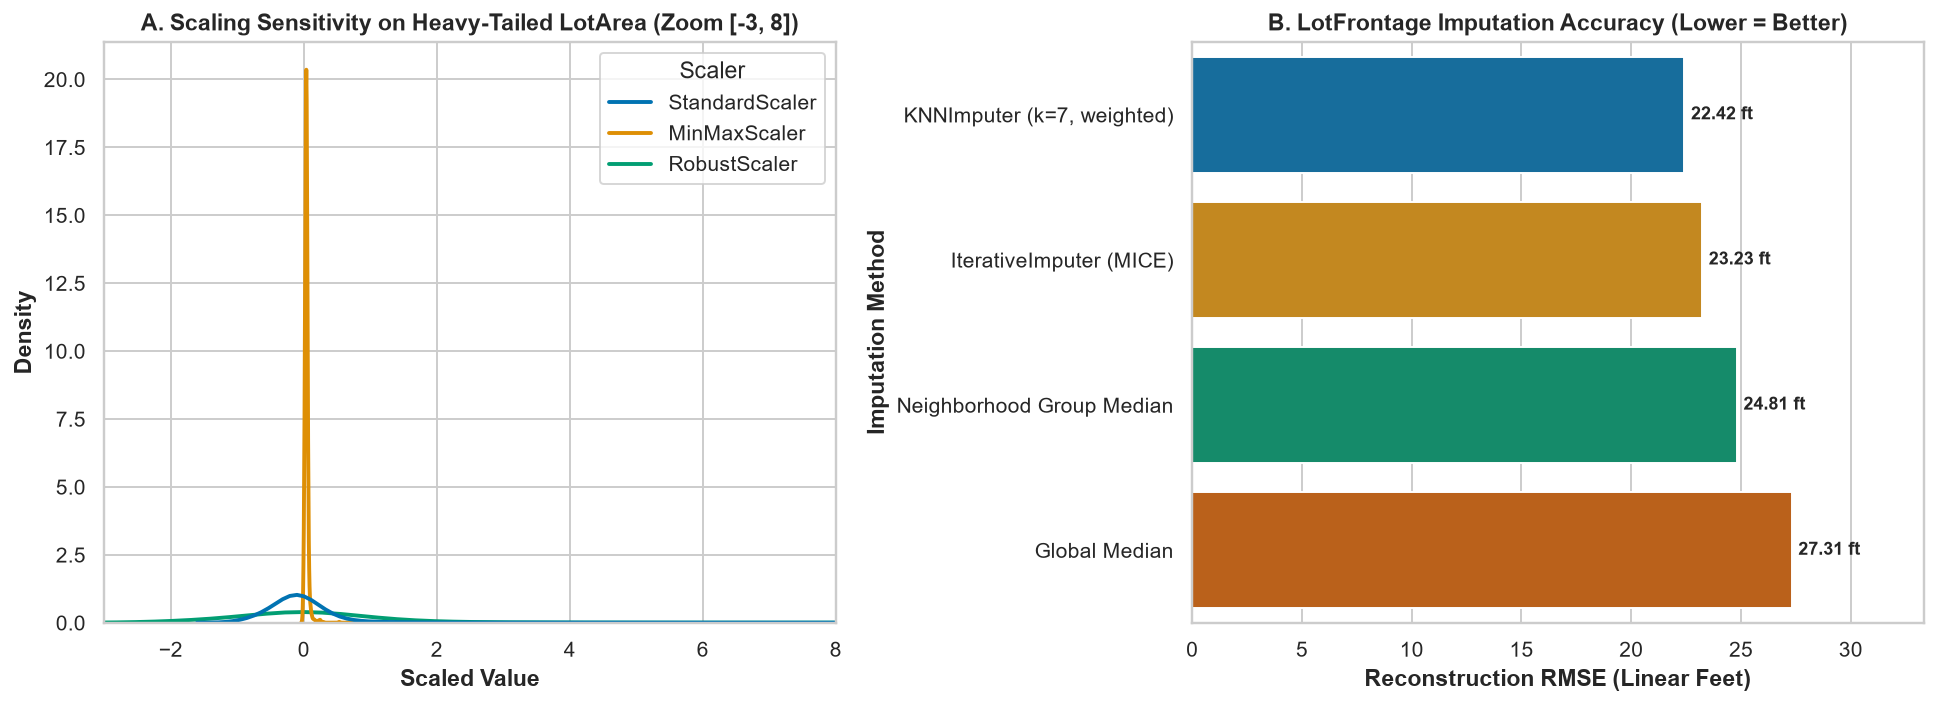

In [5]:
# Benchmark Imputers specifically on artificially masked known LotFrontage values (Train Only!)
known_lf = X_train[X_train["LotFrontage"].notnull()].copy()
lf_features = ["LotArea", "1stFlrSF", "GrLivArea", "OverallQual", "TotRmsAbvGrd", "LotFrontage"]
lf_mat = known_lf[lf_features].copy()

# Mask 20% of known LotFrontage values deterministically to measure true Imputation RMSE
rng = np.random.RandomState(RANDOM_STATE)
mask_idx = rng.choice(len(lf_mat), size=int(0.20 * len(lf_mat)), replace=False)
y_true_lf = lf_mat["LotFrontage"].iloc[mask_idx].values

# 1. Global Median
med_val = np.median(np.delete(lf_mat["LotFrontage"].values, mask_idx))
rmse_global_med = np.sqrt(mean_squared_error(y_true_lf, np.full_like(y_true_lf, med_val)))

# 2. Neighborhood Group Median
train_lf_sub = known_lf.drop(known_lf.index[mask_idx])
neigh_meds = train_lf_sub.groupby("Neighborhood")["LotFrontage"].median()
pred_group = known_lf.iloc[mask_idx]["Neighborhood"].map(neigh_meds).fillna(med_val).values
rmse_group_med = np.sqrt(mean_squared_error(y_true_lf, pred_group))

# 3. KNNImputer (standardized auxiliary features)
lf_masked = lf_mat.copy()
lf_masked.iloc[mask_idx, lf_masked.columns.get_loc("LotFrontage")] = np.nan
scaler_lf = StandardScaler()
lf_scaled = scaler_lf.fit_transform(lf_masked)
knn_imp = KNNImputer(n_neighbors=7, weights="distance")
pred_knn = scaler_lf.inverse_transform(knn_imp.fit_transform(lf_scaled))[mask_idx, -1]
rmse_knn = np.sqrt(mean_squared_error(y_true_lf, pred_knn))

# 4. IterativeImputer (MICE)
iter_imp = IterativeImputer(random_state=RANDOM_STATE, max_iter=15)
pred_iter = scaler_lf.inverse_transform(iter_imp.fit_transform(lf_scaled))[mask_idx, -1]
rmse_iter = np.sqrt(mean_squared_error(y_true_lf, pred_iter))

imp_bench = pd.DataFrame({
    "Imputation Method": ["Global Median", "Neighborhood Group Median", "KNNImputer (k=7, weighted)", "IterativeImputer (MICE)"],
    "Masked RMSE (feet)": [rmse_global_med, rmse_group_med, rmse_knn, rmse_iter],
}).sort_values("Masked RMSE (feet)")
print("=== LotFrontage Imputation Benchmark (20% Holdout Mask on Train) ===")
display(imp_bench.round(3))

# Discretization Demonstration: KBinsDiscretizer on YearBuilt (Era Buckets)
kbd = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")
year_bins = kbd.fit_transform(X_train[["YearBuilt"]]).ravel()
bin_edges = np.round(kbd.bin_edges_[0]).astype(int)
era_df = pd.DataFrame({"YearBin": year_bins, "SalePrice": y_train.values}).groupby("YearBin")["SalePrice"].agg(["count", "median", "mean"])
era_df["Era_Range"] = [f"{bin_edges[i]}–{bin_edges[i+1]}" for i in range(len(bin_edges)-1)]
print("\n=== Quantile Discretization (KBinsDiscretizer, n=5) of YearBuilt vs. SalePrice ===")
display(era_df[["Era_Range", "count", "median", "mean"]].round(0))

# FIGURE 4: Feature Scaling Comparison on Outlier-Prone LotArea & GrLivArea
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

sample_cols = X_train[["LotArea", "GrLivArea"]].copy()
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

scaled_dfs = []
for name, sc in scalers.items():
    arr = sc.fit_transform(sample_cols)
    tmp = pd.DataFrame(arr, columns=["LotArea", "GrLivArea"])
    tmp["Scaler"] = name
    scaled_dfs.append(tmp)
scaled_all = pd.concat(scaled_dfs, ignore_index=True)

sns.kdeplot(data=scaled_all, x="LotArea", hue="Scaler", ax=axes[0], common_norm=False, linewidth=2)
axes[0].set_xlim(-3, 8)
axes[0].set_title("A. Scaling Sensitivity on Heavy-Tailed LotArea (Zoom [-3, 8])")
axes[0].set_xlabel("Scaled Value")
axes[0].set_ylabel("Density")

# Panel B: Imputation Benchmark Barplot
sns.barplot(data=imp_bench, y="Imputation Method", x="Masked RMSE (feet)", ax=axes[1], palette="colorblind")
axes[1].set_title("B. LotFrontage Imputation Accuracy (Lower = Better)")
axes[1].set_xlabel("Reconstruction RMSE (Linear Feet)")
axes[1].set_xlim(0, imp_bench["Masked RMSE (feet)"].max() * 1.22)
for p in axes[1].patches:
    axes[1].text(p.get_width() + 0.3, p.get_y() + p.get_height()/2,
                 f"{p.get_width():.2f} ft", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_scaling_and_imputation.png"), dpi=300, bbox_inches="tight")
plt.show()

---
## 4. Domain-Specific, Interaction, Cyclical & Modular Pipeline Engineering (PO2, PO3, PO4)

To ensure **zero data leakage** and **production deployability**, all transformations are encapsulated in custom `scikit-learn` `BaseEstimator, TransformerMixin` transformers:

1. **`AmesDomainCleaner`**:
   - Converts `MSSubClass` to nominal string, handles MNAR structural missingness (`"None"` / `0`), creates binary amenity flags (`HasPool`, `HasGarage`, `HasBasement`, `HasFireplace`, `HasFence`, `HasMasonry`, `LotFrontage_Missing`), and imputes `LotFrontage` using training-fold `Neighborhood` medians (learned strictly in `.fit()`).
2. **`AmesDomainFeatureEngineer`**:
   - **Area Aggregations:** `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`, `TotalPorchSF`, `TotalFinBsmtSF`
   - **Functional Ratios:** `TotalBathrooms = FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath`, `LivArea_to_Lot_Ratio`, `AvgRoomSize`, `BsmtFinRatio`
   - **Temporal Dynamics:** `HouseAge = YrSold - YearBuilt`, `YearsSinceRemodel = YrSold - YearRemodAdd`, `IsRemodeled`
   - **Cyclical Month Encoding:** Maps discrete `MoSold` $\in \{1, \dots, 12\}$ onto the unit circle so December (12) and January (1) are contiguous:
     $$\text{MoSold\_sin} = \sin\!\left(\frac{2\pi \cdot \text{MoSold}}{12}\right), \qquad \text{MoSold\_cos} = \cos\!\left(\frac{2\pi \cdot \text{MoSold}}{12}\right)$$
   - **Non-Linear Interactions & Polynomials:** `Quality_x_TotalSF = OverallQual * TotalSF`, `OverallGrade = OverallQual * OverallCond`, `Qual_x_Bath = OverallQual * TotalBathrooms`, `TotalSF_sq = TotalSF²`
3. **`QuantileWinsorizer`**:
   - Clips extreme continuous tails to training-learned $[q_{0.005}, q_{0.995}]$ bounds inside `.fit()`, preventing single extreme test/train lots from distorting linear weights.

Raw features: 79 -> After Domain Cleaning (+Flags): 86 -> After Domain Engineering: 106
Remaining missing values after AmesDomainCleaner (Train): 0


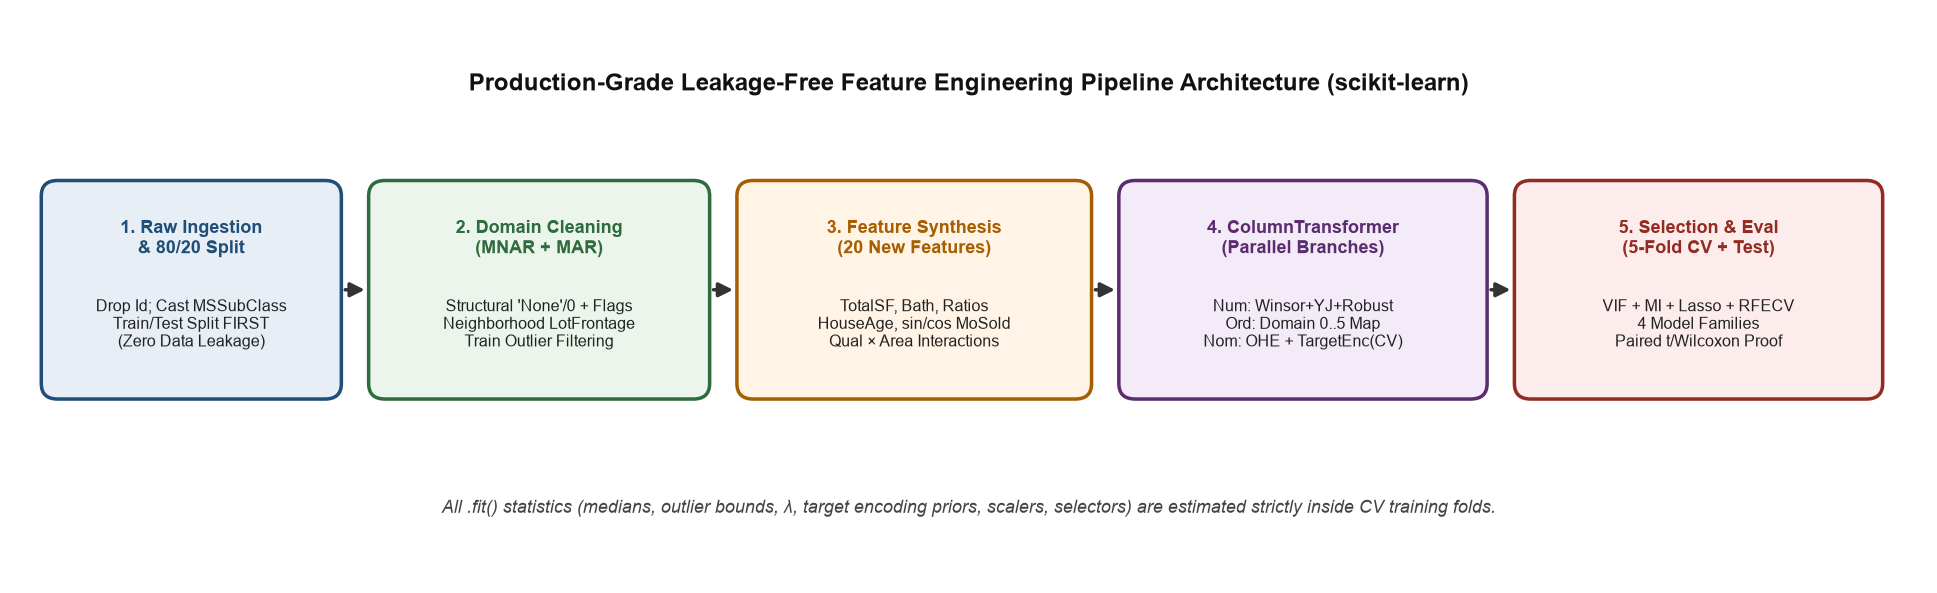

In [6]:
# Explicit Domain Ordinal Mappings
ORDINAL_MAPS = {
    "ExterQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "HeatingQC": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "FireplaceQu": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageQual": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond": ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "PoolQC": ["None", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope": ["Sev", "Mod", "Gtl"],
    "PavedDrive": ["N", "P", "Y"],
}

MNAR_CAT_COLS = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"
]
MNAR_NUM_ZERO_COLS = [
    "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea"
]


class AmesDomainCleaner(BaseEstimator, TransformerMixin):
    '''Leakage-free domain cleaner handling MNAR structural absences and MAR LotFrontage.'''

    def __init__(self):
        self.neigh_medians_ = None
        self.global_lf_median_ = None
        self.electrical_mode_ = None

    def fit(self, X, y=None):
        df = X.copy()
        self.neigh_medians_ = df.groupby("Neighborhood")["LotFrontage"].median().to_dict()
        self.global_lf_median_ = float(df["LotFrontage"].median())
        self.electrical_mode_ = df["Electrical"].mode()[0]
        return self

    def transform(self, X):
        df = X.copy()
        df["MSSubClass"] = df["MSSubClass"].astype(str)

        # Missingness / Presence Indicator Flags (captured BEFORE imputation)
        df["LotFrontage_Missing"] = df["LotFrontage"].isnull().astype(int)
        df["HasPool"] = (df["PoolArea"].fillna(0) > 0).astype(int)
        df["HasGarage"] = df["GarageType"].notnull().astype(int)
        df["HasBasement"] = (df["TotalBsmtSF"].fillna(0) > 0).astype(int)
        df["HasFireplace"] = (df["Fireplaces"].fillna(0) > 0).astype(int)
        df["HasFence"] = df["Fence"].notnull().astype(int)
        df["HasMasonry"] = (df["MasVnrArea"].fillna(0) > 0).astype(int)

        # MNAR Structural Imputation
        for col in MNAR_CAT_COLS:
            if col in df.columns:
                df[col] = df[col].fillna("None").astype(str)
        for col in MNAR_NUM_ZERO_COLS:
            if col in df.columns:
                df[col] = df[col].fillna(0.0)

        # GarageYrBlt: structural absence -> fallback to YearBuilt so GarageAge = 0
        df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])

        # MAR LotFrontage: learned Neighborhood median -> global fallback
        mapped_lf = df["Neighborhood"].map(self.neigh_medians_).fillna(self.global_lf_median_)
        df["LotFrontage"] = df["LotFrontage"].fillna(mapped_lf)

        # MCAR Electrical
        df["Electrical"] = df["Electrical"].fillna(self.electrical_mode_)
        return df


class AmesDomainFeatureEngineer(BaseEstimator, TransformerMixin):
    '''Synthesizes structural, ratio, temporal, cyclical, and interaction features.'''

    def __init__(self, add_features=True):
        self.add_features = add_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        if not self.add_features:
            return df

        # Structural Aggregations
        df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
        df["TotalFinBsmtSF"] = df["BsmtFinSF1"] + df["BsmtFinSF2"]
        df["TotalPorchSF"] = (
            df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"]
        )
        df["TotalBathrooms"] = (
            df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
        )
        df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
        df["HasPorch"] = (df["TotalPorchSF"] > 0).astype(int)

        # Ratios & Efficiency Metrics
        df["LivArea_to_Lot_Ratio"] = df["GrLivArea"] / (df["LotArea"] + 1.0)
        df["AvgRoomSize"] = df["GrLivArea"] / (df["TotRmsAbvGrd"] + 1.0)
        df["BsmtFinRatio"] = np.where(df["TotalBsmtSF"] > 0, df["TotalFinBsmtSF"] / (df["TotalBsmtSF"] + 1.0), 0.0)
        df["GarageArea_per_Car"] = np.where(df["GarageCars"] > 0, df["GarageArea"] / df["GarageCars"], 0.0)

        # Temporal & Cyclical Features
        df["HouseAge"] = np.maximum(0, df["YrSold"] - df["YearBuilt"])
        df["YearsSinceRemodel"] = np.maximum(0, df["YrSold"] - df["YearRemodAdd"])
        df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
        df["IsNewBuild"] = (df["YrSold"] == df["YearBuilt"]).astype(int)
        df["MoSold_sin"] = np.sin(2 * np.pi * df["MoSold"] / 12.0)
        df["MoSold_cos"] = np.cos(2 * np.pi * df["MoSold"] / 12.0)

        # Domain Non-Linear Interactions & Polynomial Terms
        df["Quality_x_TotalSF"] = df["OverallQual"] * df["TotalSF"]
        df["OverallGrade"] = df["OverallQual"] * df["OverallCond"]
        df["Qual_x_Bath"] = df["OverallQual"] * df["TotalBathrooms"]
        df["TotalSF_sq"] = df["TotalSF"] ** 2
        return df


class QuantileWinsorizer(BaseEstimator, TransformerMixin):
    '''Clips extreme numeric tails to training-learned quantile bounds.'''

    def __init__(self, lower_q=0.005, upper_q=0.995):
        self.lower_q = lower_q
        self.upper_q = upper_q

    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        arr = np.asarray(X, dtype=float)
        self.n_features_in_ = arr.shape[1]
        self.lower_bounds_ = np.nanquantile(arr, self.lower_q, axis=0)
        self.upper_bounds_ = np.nanquantile(arr, self.upper_q, axis=0)
        return self

    def transform(self, X):
        arr = np.asarray(X, dtype=float)
        return np.clip(arr, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)


# Smoke-test transformers on X_train
cleaner = AmesDomainCleaner()
engineer = AmesDomainFeatureEngineer(add_features=True)
X_tr_clean = cleaner.fit_transform(X_train)
X_tr_eng = engineer.fit_transform(X_tr_clean)
print(f"Raw features: {X_train.shape[1]} -> After Domain Cleaning (+Flags): {X_tr_clean.shape[1]} -> After Domain Engineering: {X_tr_eng.shape[1]}")
print("Remaining missing values after AmesDomainCleaner (Train):", X_tr_clean.isnull().sum().sum())

# FIGURE 5: End-to-End Leakage-Free Feature Engineering Architecture Diagram
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4.4)
ax.axis("off")

boxes = [
    (0.3, 1.5, 2.0, 1.5, "#E8EEF5", "#1F4E79", "1. Raw Ingestion\n& 80/20 Split", "Drop Id; Cast MSSubClass\nTrain/Test Split FIRST\n(Zero Data Leakage)"),
    (2.7, 1.5, 2.3, 1.5, "#EBF5EB", "#2E6B3E", "2. Domain Cleaning\n(MNAR + MAR)", "Structural 'None'/0 + Flags\nNeighborhood LotFrontage\nTrain Outlier Filtering"),
    (5.4, 1.5, 2.4, 1.5, "#FFF4E5", "#A65E00", "3. Feature Synthesis\n(20 New Features)", "TotalSF, Bath, Ratios\nHouseAge, sin/cos MoSold\nQual × Area Interactions"),
    (8.2, 1.5, 2.5, 1.5, "#F3EBF7", "#5B2C6F", "4. ColumnTransformer\n(Parallel Branches)", "Num: Winsor+YJ+Robust\nOrd: Domain 0..5 Map\nNom: OHE + TargetEnc(CV)"),
    (11.1, 1.5, 2.5, 1.5, "#FCECEC", "#922B21", "5. Selection & Eval\n(5-Fold CV + Test)", "VIF + MI + Lasso + RFECV\n4 Model Families\nPaired t/Wilcoxon Proof"),
]

for x, y, w, h, fc, ec, title, body in boxes:
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1,rounding_size=0.12",
                                   facecolor=fc, edgecolor=ec, linewidth=1.8)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h - 0.35, title, ha="center", va="center", fontsize=9.5, fontweight="bold", color=ec)
    ax.text(x + w/2, y + 0.48, body, ha="center", va="center", fontsize=8, color="#222222")

for i in range(len(boxes) - 1):
    x1 = boxes[i][0] + boxes[i][2] + 0.1
    x2 = boxes[i+1][0] - 0.1
    ym = 2.25
    ax.annotate("", xy=(x2, ym), xytext=(x1, ym),
                arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.8, mutation_scale=15))

ax.text(7.0, 3.85, "Production-Grade Leakage-Free Feature Engineering Pipeline Architecture (scikit-learn)",
        ha="center", va="center", fontsize=12.5, fontweight="bold", color="#111111")
ax.text(7.0, 0.55, "All .fit() statistics (medians, outlier bounds, λ, target encoding priors, scalers, selectors) are estimated strictly inside CV training folds.",
        ha="center", va="center", fontsize=9, style="italic", color="#444444")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_pipeline_architecture.png"), dpi=300, bbox_inches="tight")
plt.show()

---
## 5. Multicollinearity (VIF), Feature Selection & Dimensionality Reduction (PO1, PO2, PO4)

### 5.1 Variance Inflation Factor (VIF)
Multicollinearity inflates linear coefficient variance $\text{Var}(\hat{\beta}_j) \propto \text{VIF}_j$:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
where $R_j^2$ is the coefficient of determination obtained by regressing feature $X_j$ on all remaining predictors. Values $\text{VIF} > 10$ indicate severe collinearity (e.g., `TotalSF` vs constituent `1stFlrSF`, `2ndFlrSF`, `TotalBsmtSF`; `GarageArea` vs `GarageCars`; `GrLivArea` vs `TotRmsAbvGrd`).

### 5.2 Multi-Paradigm Feature Selection
1. **Filter Methods:** Model-agnostic statistical scoring via **Mutual Information** $I(X;Y) = \iint p(x,y)\log\frac{p(x,y)}{p(x)p(y)}\,dx\,dy$ (captures non-linear dependencies), Pearson $r$, Spearman $\rho$, and univariate $F$-test.
2. **Embedded Methods:**
   - **LassoCV ($L_1$ Regularization):** $\min_{\beta} \frac{1}{2n}\|y - X\beta\|_2^2 + \alpha \|\beta\|_1$, driving redundant weights identically to zero.
   - **Random Forest Permutation Importance:** Measures mean CV score degradation when feature $j$ is randomly permuted.
3. **Wrapper Method (`RFECV`):** Iteratively prunes lowest-weight features using 5-fold CV to locate the parsimonious optimum.

### 5.3 Principal Component Analysis (PCA)
Projects standardized features $\tilde{X}$ onto orthogonal eigenvectors $\mathbf{v}_k$ of the sample covariance matrix $\Sigma = \frac{1}{n-1}\tilde{X}^T\tilde{X}$, ranking components by explained variance ratio $\frac{\lambda_k}{\sum_j \lambda_j}$.

=== Variance Inflation Factor (VIF) Before vs. After Collinear Feature Pruning ===


C:\Users\Harshal Pawar\.gemini\antigravity\scratch\AIML_Assignment_2_Feature_Engineering\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Harshal Pawar\.gemini\antigravity\scratch\AIML_Assignment_2_Feature_Engineering\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Harshal Pawar\.gemini\antigravity\scratch\AIML_Assignment_2_Feature_Engineering\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Harshal Pawar\.gemini\antigravity\scratch\AIML_Assignment_2_Feat

,Feature,VIF_Before,VIF_After
0,GrLivArea,1.283300e+02,5.10
1,1stFlrSF,1.000800e+15,NaN
2,2ndFlrSF,1.000800e+15,NaN
3,TotalBsmtSF,1.000800e+15,NaN
4,TotalSF,1.000800e+15,5.14
5,TotRmsAbvGrd,3.240000e+00,NaN
6,GarageCars,5.200000e+00,1.83
7,GarageArea,4.940000e+00,NaN
8,OverallQual,2.490000e+00,2.44
9,HouseAge,2.160000e+00,2.14


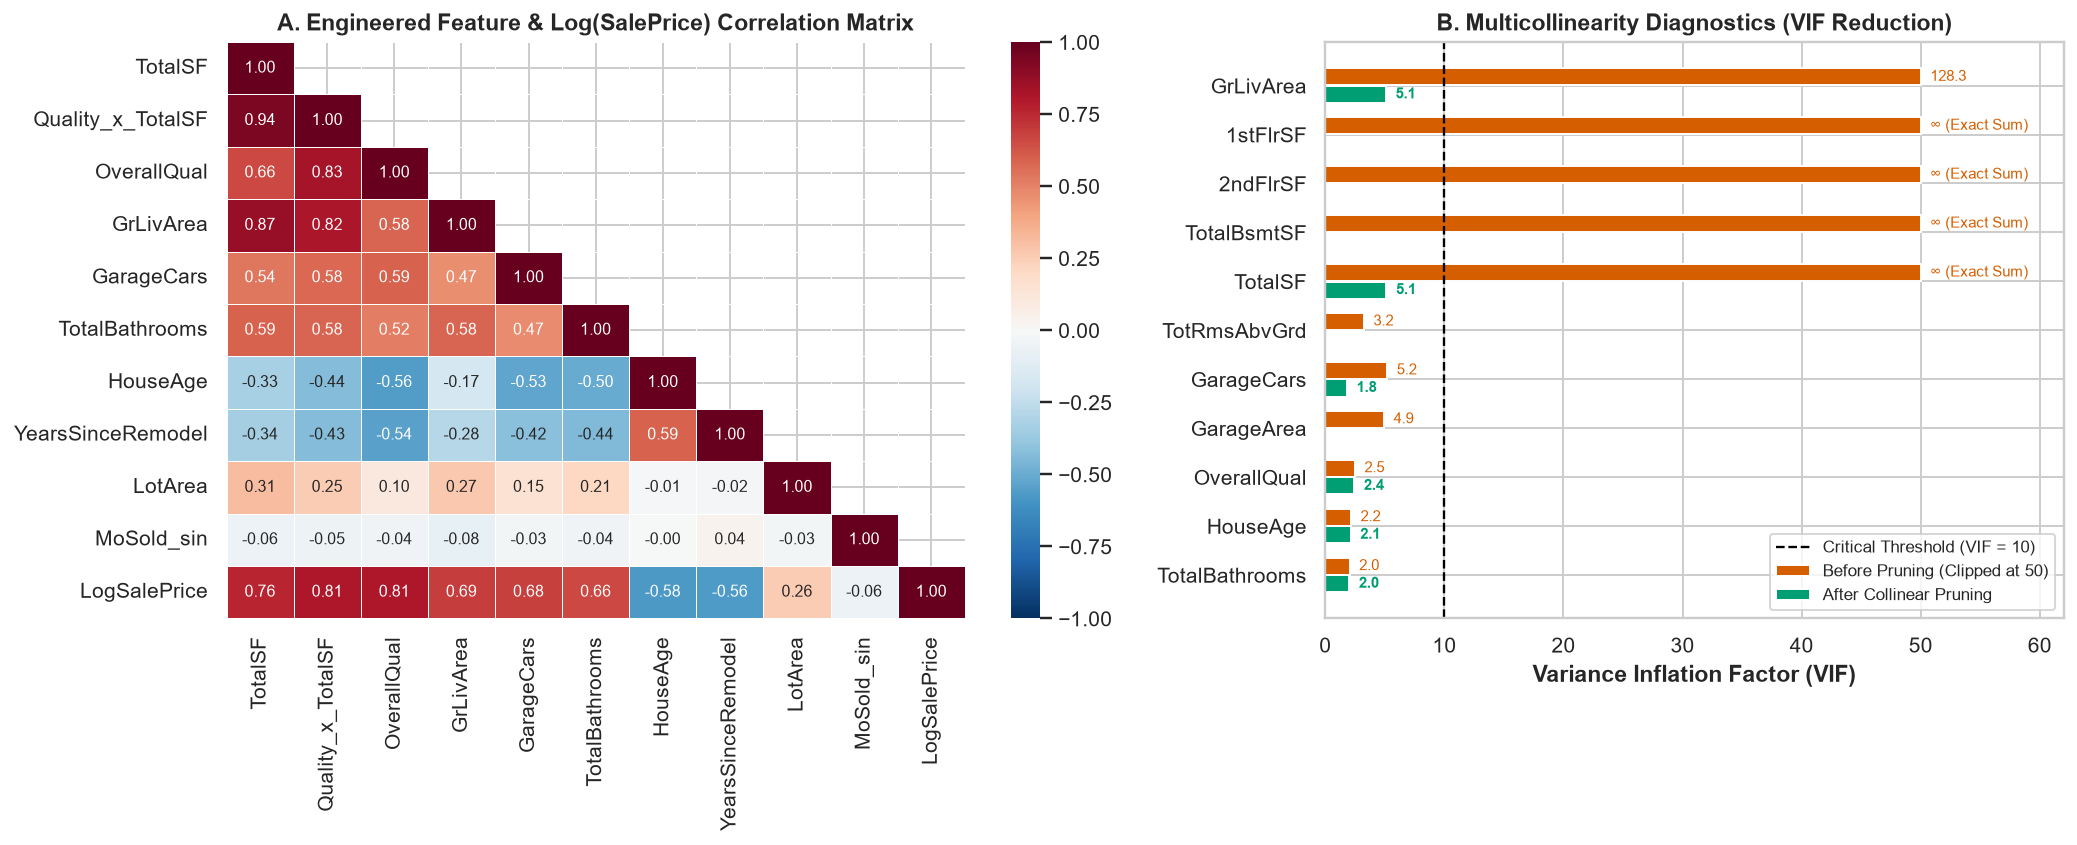

In [7]:
# Helper to build full ColumnTransformer for Stage 3 (Engineered Features)
def build_preprocessor(X_sample, use_engineered=True, scale_mode="robust", use_yj=True):
    num_cols = X_sample.select_dtypes(include=[np.number]).columns.tolist()
    ord_cols = [c for c in ORDINAL_MAPS.keys() if c in X_sample.columns]
    high_card_nom = [c for c in ["Neighborhood", "Exterior1st", "Exterior2nd"] if c in X_sample.columns]
    low_nom_cols = [
        c for c in X_sample.columns
        if c not in num_cols and c not in ord_cols and c not in high_card_nom
    ]

    num_steps = [("imputer", SimpleImputer(strategy="median")), ("winsor", QuantileWinsorizer(0.005, 0.995))]
    if use_yj:
        num_steps.append(("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)))
    if scale_mode == "robust":
        num_steps.append(("scaler", RobustScaler()))
    elif scale_mode == "standard":
        num_steps.append(("scaler", StandardScaler()))
    elif scale_mode == "minmax":
        num_steps.append(("scaler", MinMaxScaler()))

    ord_categories = [ORDINAL_MAPS[c] for c in ord_cols]
    ord_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
        ("ord_enc", OrdinalEncoder(categories=ord_categories, handle_unknown="use_encoded_value", unknown_value=-1)),
        ("scaler", StandardScaler()),
    ])

    nom_low_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=15, sparse_output=False)),
    ])

    nom_high_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("target_enc", TargetEncoder(cv=5, smooth="auto", random_state=RANDOM_STATE)),
        ("scaler", StandardScaler()),
    ])

    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("ord", ord_pipe, ord_cols),
        ("nom_low", nom_low_pipe, low_nom_cols),
        ("nom_high", nom_high_pipe, high_card_nom),
    ], remainder="drop", verbose_feature_names_out=False)


# 1. Multicollinearity (VIF) Audit on Key Numerical & Engineered Predictors
collinear_subset_before = [
    "GrLivArea", "1stFlrSF", "2ndFlrSF", "TotalBsmtSF", "TotalSF",
    "TotRmsAbvGrd", "GarageCars", "GarageArea", "OverallQual", "HouseAge", "TotalBathrooms"
]
X_vif_before = StandardScaler().fit_transform(X_tr_eng[collinear_subset_before].fillna(0))
vif_before = pd.DataFrame({
    "Feature": collinear_subset_before,
    "VIF_Before": [variance_inflation_factor(X_vif_before, i) for i in range(len(collinear_subset_before))]
})

# Pruned subset removing exact linear sums (1stFlrSF, 2ndFlrSF, TotalBsmtSF) & redundant proxies (GarageArea, TotRmsAbvGrd)
collinear_subset_after = [
    "TotalSF", "GrLivArea", "GarageCars", "OverallQual", "HouseAge", "TotalBathrooms"
]
X_vif_after = StandardScaler().fit_transform(X_tr_eng[collinear_subset_after].fillna(0))
vif_after = pd.DataFrame({
    "Feature": collinear_subset_after,
    "VIF_After": [variance_inflation_factor(X_vif_after, i) for i in range(len(collinear_subset_after))]
})

vif_summary = vif_before.merge(vif_after, on="Feature", how="left")
print("=== Variance Inflation Factor (VIF) Before vs. After Collinear Feature Pruning ===")
display(vif_summary.round(2))

# FIGURE 6: Correlation Heatmap & VIF Reduction
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})

corr_cols = ["TotalSF", "Quality_x_TotalSF", "OverallQual", "GrLivArea", "GarageCars",
             "TotalBathrooms", "HouseAge", "YearsSinceRemodel", "LotArea", "MoSold_sin"]
corr_df = X_tr_eng[corr_cols].copy()
corr_df["LogSalePrice"] = y_train_log.values
corr_mat = corr_df.corr()

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("A. Engineered Feature & Log(SalePrice) Correlation Matrix")

# Panel B: VIF Before vs After (log scale capped for visual clarity)
vif_plot = vif_summary.copy()
vif_plot["VIF_Before_Plot"] = vif_plot["VIF_Before"].clip(upper=50)
y_pos = np.arange(len(vif_plot))
axes[1].barh(y_pos - 0.18, vif_plot["VIF_Before_Plot"], height=0.35, color=PALETTE[3], label="Before Pruning (Clipped at 50)")
axes[1].barh(y_pos + 0.18, vif_plot["VIF_After"].fillna(0), height=0.35, color=PALETTE[2], label="After Collinear Pruning")
axes[1].axvline(10, color="black", linestyle="--", linewidth=1.2, label="Critical Threshold (VIF = 10)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(vif_plot["Feature"])
axes[1].invert_yaxis()
axes[1].set_xlabel("Variance Inflation Factor (VIF)")
axes[1].set_xlim(0, 62)
axes[1].set_title("B. Multicollinearity Diagnostics (VIF Reduction)")
axes[1].legend(loc="lower right", frameon=True, fontsize=8.5)

for i, (vb, va) in enumerate(zip(vif_plot["VIF_Before"], vif_plot["VIF_After"])):
    lbl_b = "∞ (Exact Sum)" if vb > 1e5 else f"{vb:.1f}"
    axes[1].text(min(vb, 50) + 0.8, i - 0.18, lbl_b, va="center", fontsize=7.5, color=PALETTE[3])
    if pd.notnull(va):
        axes[1].text(va + 0.8, i + 0.18, f"{va:.1f}", va="center", fontsize=7.5, color=PALETTE[2], fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig6_correlation_and_vif.png"), dpi=300, bbox_inches="tight")
plt.show()

Encoded Stage-3 Feature Matrix (Train): 1166 samples x 181 features


LassoCV optimal alpha = 0.00070, non-zero features = 90 / 181


RFECV Optimal Feature Count: 105 features (Best CV RMSLE = 0.11407)

=== Top 15 Consensus Features Across Filter, Embedded & Wrapper Paradigms ===


,Feature,Mutual_Info,F_Score,Lasso_Abs_Coef,RF_Perm_Importance,RFECV_Selected,Consensus_Rank
42,TotalSF,0.6380,2423.7069,0.0690,0.0011,True,6.6667
178,Neighborhood,0.4777,1359.9581,0.0305,0.0317,True,7.3333
49,AvgRoomSize,0.3465,864.8630,0.0430,0.0018,True,8.6667
52,HouseAge,0.3454,706.8883,0.0373,0.0015,True,10.3333
25,GarageArea,0.3629,898.1214,0.0194,0.0033,True,12.6667
60,Qual_x_Bath,0.6962,2428.7116,0.0167,0.0056,True,13.0000
59,OverallGrade,0.3880,664.6460,0.0190,0.0021,True,13.6667
1,LotArea,0.1940,256.0242,0.0315,0.0023,True,16.0000
2,OverallQual,0.5352,2165.8926,0.0449,0.0002,True,22.0000
11,1stFlrSF,0.2902,654.6056,0.0128,0.0013,True,24.6667


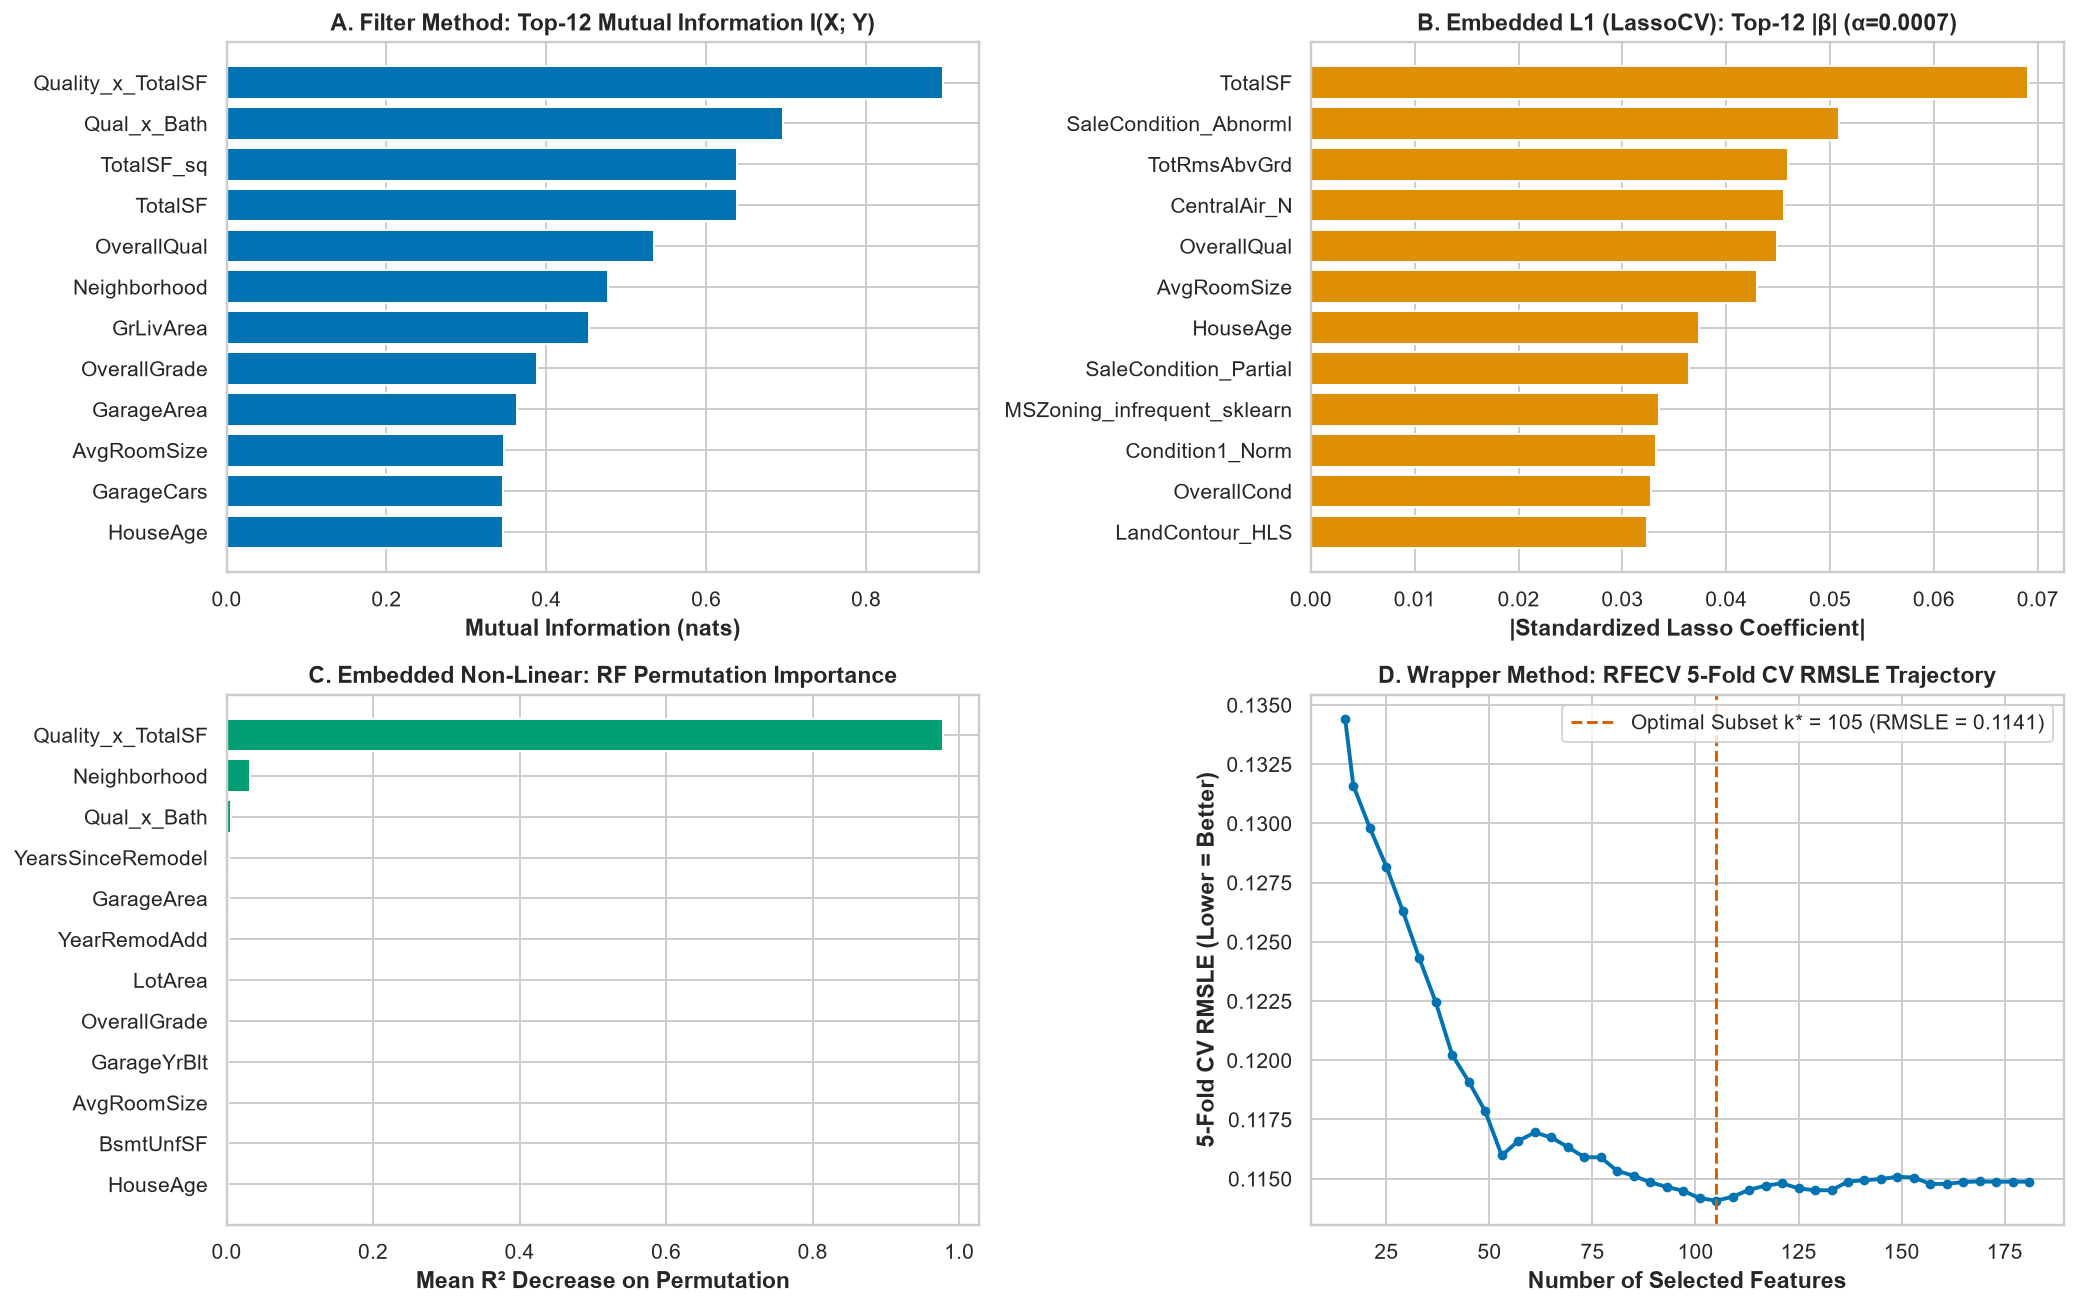

In [8]:
# Prepare full Stage-3 design matrix on X_train ONLY for feature selection diagnostics
# Remove the 2 extreme partial-sale anomalies ONLY in training set
train_keep_mask = ~((X_train["GrLivArea"] > 4000) & (y_train < 300000))
X_tr_no_out = X_train.loc[train_keep_mask].copy()
y_tr_log_no_out = y_train_log.loc[train_keep_mask].copy()

X_tr_stage3_raw = engineer.fit_transform(cleaner.fit_transform(X_tr_no_out))
pre_stage3 = build_preprocessor(X_tr_stage3_raw, use_engineered=True, scale_mode="standard", use_yj=True)
X_tr_mat = pre_stage3.fit_transform(X_tr_stage3_raw, y_tr_log_no_out)
feat_names = pre_stage3.get_feature_names_out()
print(f"Encoded Stage-3 Feature Matrix (Train): {X_tr_mat.shape[0]} samples x {X_tr_mat.shape[1]} features")

# 1. Filter: Mutual Information & F-Regression
mi_scores = mutual_info_regression(X_tr_mat, y_tr_log_no_out, random_state=RANDOM_STATE)
f_scores, f_pvals = f_regression(X_tr_mat, y_tr_log_no_out)

# 2. Embedded: LassoCV (L1)
lasso_cv = LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=5000, n_jobs=-1)
lasso_cv.fit(X_tr_mat, y_tr_log_no_out)
lasso_abs = np.abs(lasso_cv.coef_)
print(f"LassoCV optimal alpha = {lasso_cv.alpha_:.5f}, non-zero features = {(lasso_abs > 1e-6).sum()} / {len(feat_names)}")

# 3. Embedded: Random Forest Permutation Importance (via internal validation split on train)
X_sub_tr, X_sub_va, y_sub_tr, y_sub_va = train_test_split(X_tr_mat, y_tr_log_no_out, test_size=0.2, random_state=RANDOM_STATE)
rf_sel = RandomForestRegressor(n_estimators=150, max_depth=14, random_state=RANDOM_STATE, n_jobs=-1)
rf_sel.fit(X_sub_tr, y_sub_tr)
perm_res = permutation_importance(rf_sel, X_sub_va, y_sub_va, n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = perm_res.importances_mean

# 4. Wrapper: RFECV with Ridge Regression
rfecv = RFECV(
    estimator=Ridge(alpha=10.0, random_state=RANDOM_STATE),
    step=4,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    min_features_to_select=15,
    n_jobs=-1,
)
rfecv.fit(X_tr_mat, y_tr_log_no_out)
print(f"RFECV Optimal Feature Count: {rfecv.n_features_} features (Best CV RMSLE = {-rfecv.cv_results_['mean_test_score'].max():.5f})")

# Combine Rankings
sel_df = pd.DataFrame({
    "Feature": feat_names,
    "Mutual_Info": mi_scores,
    "F_Score": f_scores,
    "Lasso_Abs_Coef": lasso_abs,
    "RF_Perm_Importance": perm_imp,
    "RFECV_Selected": rfecv.support_,
})
sel_df["Consensus_Rank"] = (
    sel_df["Mutual_Info"].rank(ascending=False)
    + sel_df["Lasso_Abs_Coef"].rank(ascending=False)
    + sel_df["RF_Perm_Importance"].rank(ascending=False)
) / 3.0
sel_df = sel_df.sort_values("Consensus_Rank")
print("\n=== Top 15 Consensus Features Across Filter, Embedded & Wrapper Paradigms ===")
display(sel_df.head(15).round(4))

# FIGURE 7: Feature Selection Convergence Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

top_mi = sel_df.sort_values("Mutual_Info", ascending=False).head(12).iloc[::-1]
axes[0, 0].barh(top_mi["Feature"], top_mi["Mutual_Info"], color=PALETTE[0])
axes[0, 0].set_title("A. Filter Method: Top-12 Mutual Information I(X; Y)")
axes[0, 0].set_xlabel("Mutual Information (nats)")

top_lasso = sel_df.sort_values("Lasso_Abs_Coef", ascending=False).head(12).iloc[::-1]
axes[0, 1].barh(top_lasso["Feature"], top_lasso["Lasso_Abs_Coef"], color=PALETTE[1])
axes[0, 1].set_title(f"B. Embedded L1 (LassoCV): Top-12 |β| (α={lasso_cv.alpha_:.4f})")
axes[0, 1].set_xlabel("|Standardized Lasso Coefficient|")

top_perm = sel_df.sort_values("RF_Perm_Importance", ascending=False).head(12).iloc[::-1]
axes[1, 0].barh(top_perm["Feature"], top_perm["RF_Perm_Importance"], color=PALETTE[2])
axes[1, 0].set_title("C. Embedded Non-Linear: RF Permutation Importance")
axes[1, 0].set_xlabel("Mean R² Decrease on Permutation")

n_feats_grid = rfecv.cv_results_["n_features"]
cv_rmsle_curve = -rfecv.cv_results_["mean_test_score"]
axes[1, 1].plot(n_feats_grid, cv_rmsle_curve, marker="o", markersize=4, color=PALETTE[0], linewidth=2)
axes[1, 1].axvline(rfecv.n_features_, color=PALETTE[3], linestyle="--", linewidth=1.5,
                   label=f"Optimal Subset k* = {rfecv.n_features_} (RMSLE = {cv_rmsle_curve.min():.4f})")
axes[1, 1].set_title("D. Wrapper Method: RFECV 5-Fold CV RMSLE Trajectory")
axes[1, 1].set_xlabel("Number of Selected Features")
axes[1, 1].set_ylabel("5-Fold CV RMSLE (Lower = Better)")
axes[1, 1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig7_feature_selection_convergence.png"), dpi=300, bbox_inches="tight")
plt.show()

Total encoded dimensions: 181
Components for 90% variance: 39 (21.5% of dims)
Components for 95% variance: 53 (29.3% of dims)


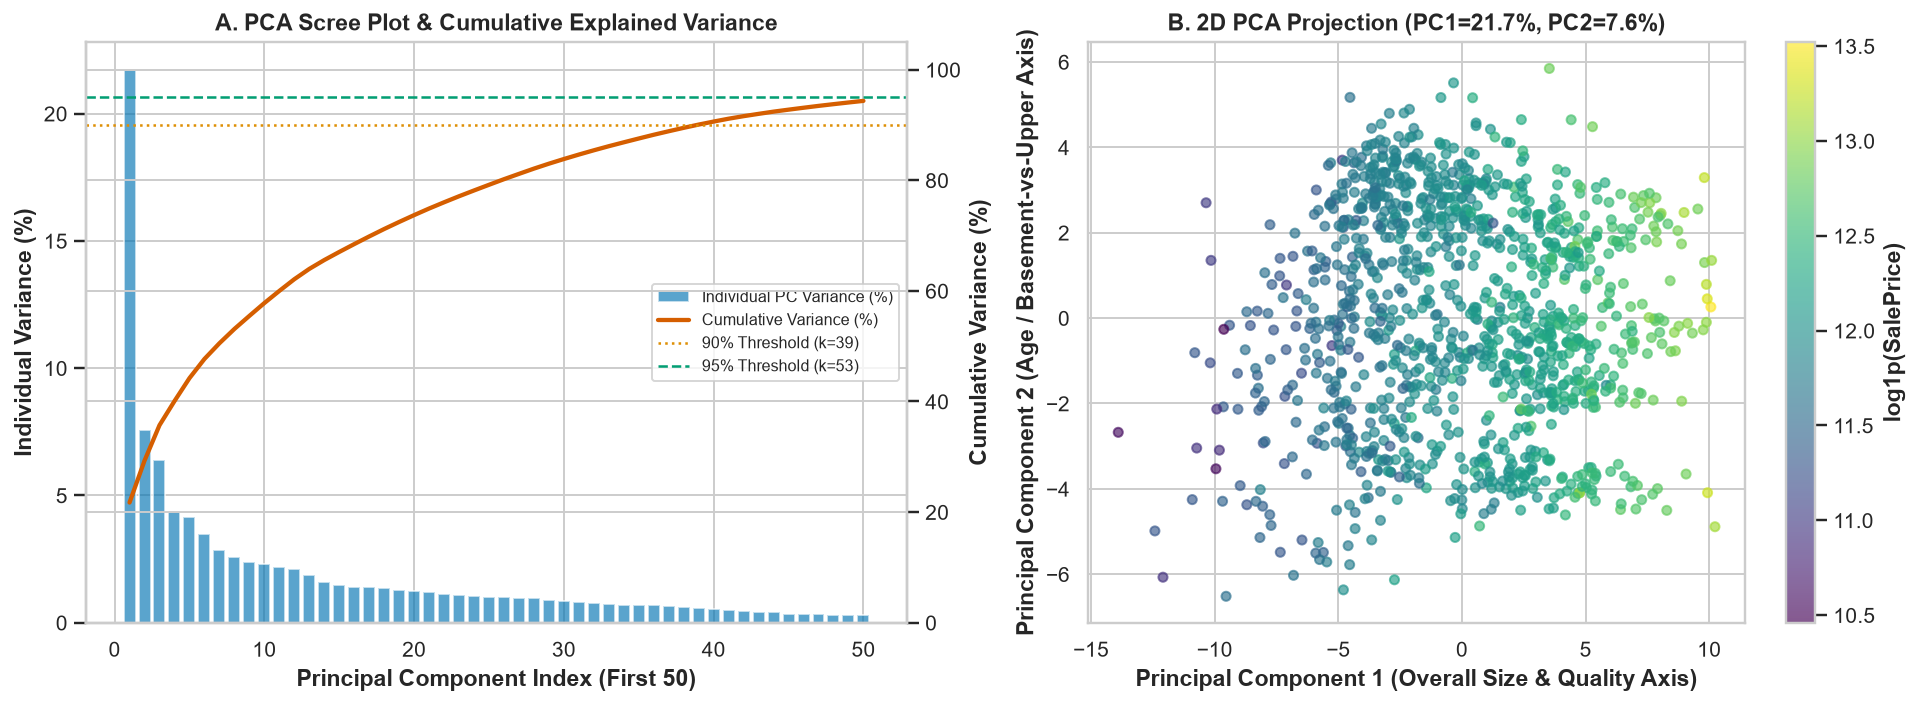

In [9]:
# PCA Dimensionality Reduction Analysis on Standardized Stage-3 Matrix
pca_full = PCA(random_state=RANDOM_STATE)
X_pca = pca_full.fit_transform(X_tr_mat)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"Total encoded dimensions: {X_tr_mat.shape[1]}")
print(f"Components for 90% variance: {n_90} ({100*n_90/X_tr_mat.shape[1]:.1f}% of dims)")
print(f"Components for 95% variance: {n_95} ({100*n_95/X_tr_mat.shape[1]:.1f}% of dims)")

# FIGURE 8: PCA Scree & Cumulative Variance + 2D Latent Price Gradient
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

k_show = min(50, len(cum_var))
axes[0].bar(range(1, k_show + 1), pca_full.explained_variance_ratio_[:k_show] * 100,
            color=PALETTE[0], alpha=0.65, label="Individual PC Variance (%)")
ax_cum = axes[0].twinx()
ax_cum.plot(range(1, k_show + 1), cum_var[:k_show] * 100, color=PALETTE[3], linewidth=2.2, label="Cumulative Variance (%)")
ax_cum.axhline(90, color=PALETTE[1], linestyle=":", linewidth=1.3, label=f"90% Threshold (k={n_90})")
ax_cum.axhline(95, color=PALETTE[2], linestyle="--", linewidth=1.3, label=f"95% Threshold (k={n_95})")
ax_cum.spines["top"].set_visible(False)

axes[0].set_title("A. PCA Scree Plot & Cumulative Explained Variance")
axes[0].set_xlabel("Principal Component Index (First 50)")
axes[0].set_ylabel("Individual Variance (%)")
ax_cum.set_ylabel("Cumulative Variance (%)")
ax_cum.set_ylim(0, 105)
lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax_cum.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc="center right", frameon=True, fontsize=8)

sc = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_tr_log_no_out, cmap="viridis", alpha=0.65, s=22)
cbar = plt.colorbar(sc, ax=axes[1])
cbar.set_label("log1p(SalePrice)")
axes[1].set_title(f"B. 2D PCA Projection (PC1={100*pca_full.explained_variance_ratio_[0]:.1f}%, PC2={100*pca_full.explained_variance_ratio_[1]:.1f}%)")
axes[1].set_xlabel("Principal Component 1 (Overall Size & Quality Axis)")
axes[1].set_ylabel("Principal Component 2 (Age / Basement-vs-Upper Axis)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig8_pca_scree_projection.png"), dpi=300, bbox_inches="tight")
plt.show()

---
## 6. Progressive Feature Engineering Ablation Study & Statistical Significance Testing (PO3, PO4, PO5)

To rigorously prove that our feature engineering yields genuine predictive improvements rather than noise, we run a **5-Stage Progressive Ablation Experiment** evaluated via **5-Fold Cross-Validation** across **4 architecturally distinct estimators**:
- **Linear Regularized:** `Ridge(alpha=15.0)`
- **Instance/Distance-Based:** `KNeighborsRegressor(n_neighbors=11, weights='distance')`
- **Bagged Decision Ensemble:** `RandomForestRegressor(n_estimators=180, random_state=42)`
- **Gradient Boosted Trees:** `HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42)`

### Progressive Pipeline Stages
- **Stage 0 (Raw Baseline):** Naive global median/mode imputation + standard OneHotEncoder on raw columns; raw `SalePrice` target (no log transform, no scaling, no domain features).
- **Stage 1 (Clean Data Preparation):** Domain MNAR/MAR imputation + indicator flags + Ordinal encoding + Smoothed Target Encoding + train outlier removal.
- **Stage 2 (+ Distributional Transforms & Scaling):** `log1p(SalePrice)` target transformation + Quantile Winsorization + Yeo–Johnson skewness correction + RobustScaler.
- **Stage 3 (+ Domain, Cyclical & Interaction Engineering):** Full `AmesDomainFeatureEngineer` (+21 engineered features).
- **Stage 4 (+ Feature Selection / PCA):** Comparing **Stage 4a (Consensus Selected Features via `SelectFromModel` LassoCV inside CV folds)** and **Stage 4b (PCA 95% Variance Projection)**.

Finally, we validate the improvement from **Stage 0 → Stage 3/4a** using **Paired $t$-tests** and **Wilcoxon Signed-Rank Tests** on fold-wise RMSLE scores, and evaluate on the **strictly unseen 20% test set**.

=== 5-Fold Cross-Validation Ablation Benchmark (X_train) ===


,Stage,Model,CV_RMSLE_Mean,CV_RMSLE_Std,CV_RMSE_USD,CV_MAE_USD,CV_R2
0,Stage 0: Raw Baseline,Ridge,0.1528,0.0130,31641.5519,17975.8619,0.8273
1,Stage 0: Raw Baseline,KNN,0.2257,0.0157,47027.5255,29985.5442,0.6278
2,Stage 0: Raw Baseline,RandomForest,0.1484,0.0189,30284.9103,18249.7293,0.8439
3,Stage 0: Raw Baseline,HistGBR,0.1334,0.0181,28472.6417,16384.6680,0.8623
4,Stage 1: Clean Prep + Encoding,Ridge,0.1272,0.0247,29883.2702,15156.0810,0.8920
5,Stage 1: Clean Prep + Encoding,KNN,0.2243,0.0147,47785.6172,30174.4253,0.6692
6,Stage 1: Clean Prep + Encoding,RandomForest,0.1448,0.0179,30195.8048,17799.0182,0.8617
7,Stage 1: Clean Prep + Encoding,HistGBR,0.1279,0.0185,26307.9330,15886.6820,0.8920
8,Stage 2: + Yeo-Johnson & Scaling,Ridge,0.1231,0.0170,27441.5303,15285.3911,0.9000
9,Stage 2: + Yeo-Johnson & Scaling,KNN,0.1711,0.0161,37050.6209,22151.9661,0.8073



=== Statistical Significance: Stage 0 vs. Stage 3 (5-Fold Paired Tests) ===


,Model,Stage0_RMSLE,Stage3_RMSLE,RMSLE_Reduction_%,Paired_t_stat,Paired_t_pval,Wilcoxon_pval
0,Ridge,0.15281,0.12167,20.37812,6.23816,0.00336,0.0625
1,KNN,0.22570,0.17003,24.66267,17.19443,0.00007,0.0625
2,RandomForest,0.14845,0.14181,4.46864,2.79501,0.04906,0.1250
3,HistGBR,0.13342,0.12774,4.25258,3.60486,0.02266,0.0625



=== Strictly Held-Out 20% Test Set Evaluation (n = 292) ===


,Model,Pipeline,Test_RMSLE,Test_RMSE_USD,Test_MAE_USD,Test_R2
0,Ridge,Stage 0 (Raw Baseline),0.1587,30786.9984,18783.4201,0.8764
1,Ridge,Stage 3 (Engineered),0.1256,26136.7520,15058.4762,0.9154
2,KNN,Stage 0 (Raw Baseline),0.2340,50627.8564,28756.6921,0.6658
3,KNN,Stage 3 (Engineered),0.1787,37379.1706,21041.0763,0.8290
4,RandomForest,Stage 0 (Raw Baseline),0.1527,28193.0491,17387.5881,0.8964
5,RandomForest,Stage 3 (Engineered),0.1408,27767.3800,16213.7790,0.8937
6,HistGBR,Stage 0 (Raw Baseline),0.1432,29458.6803,16832.2809,0.8869
7,HistGBR,Stage 3 (Engineered),0.1357,27006.3875,15680.3980,0.9013


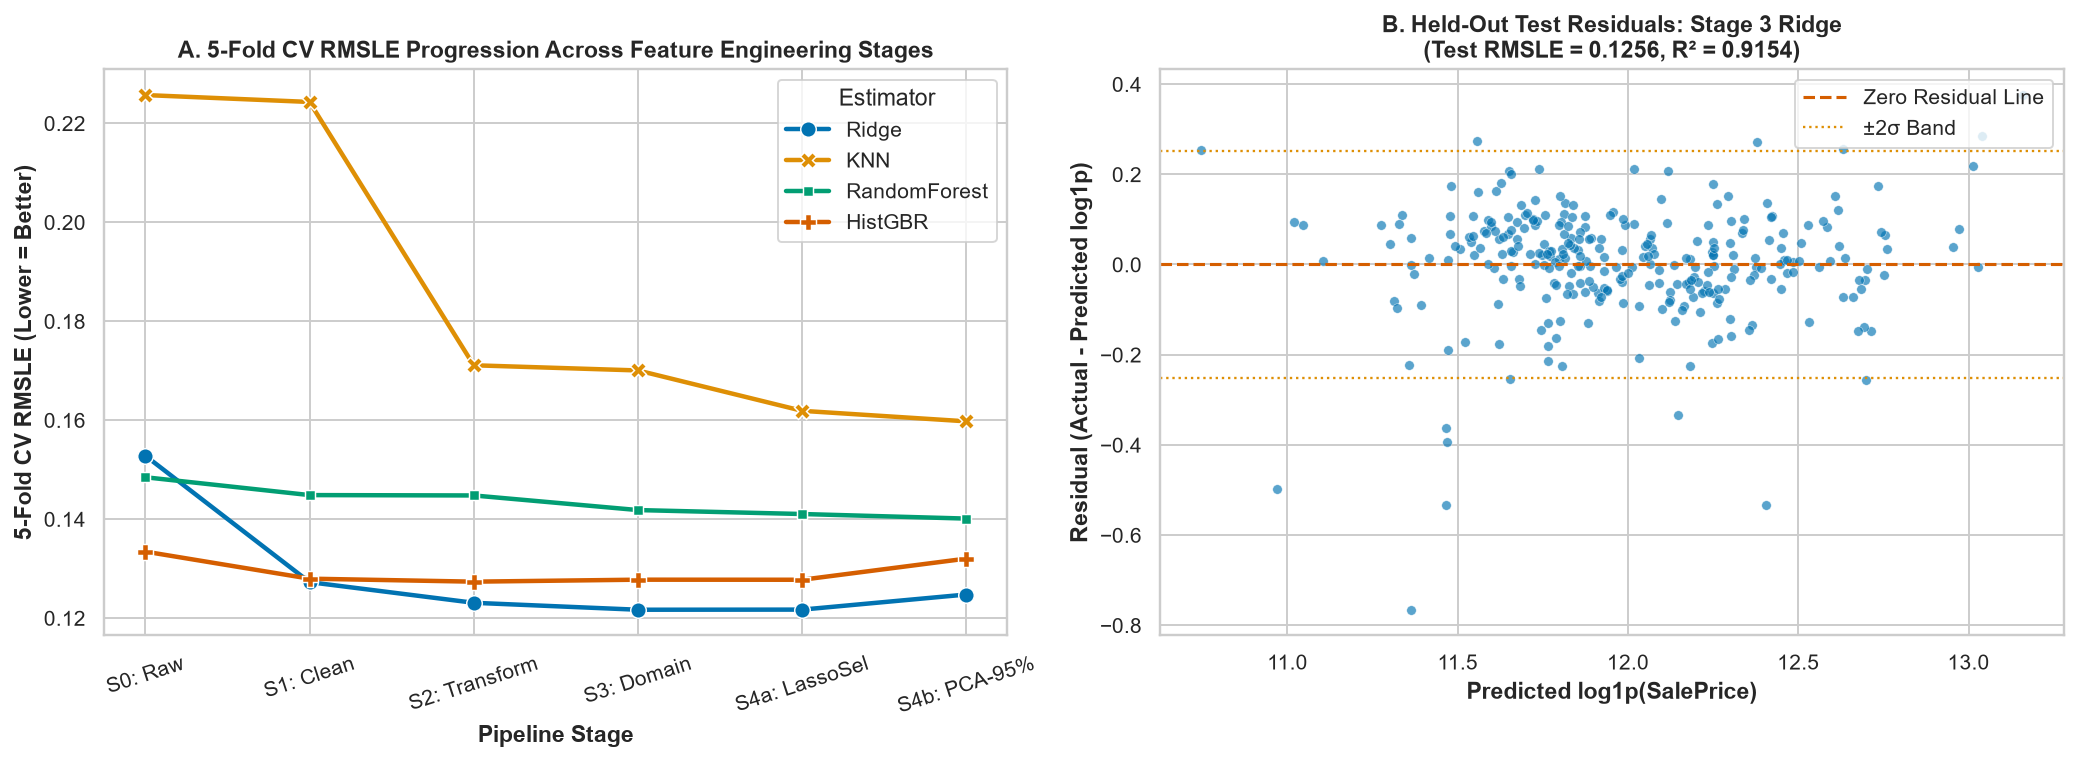

Saved verified metrics to results_summary.json


In [10]:
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def eval_pipeline_cv(pipe_builder, X_data, y_data_raw, log_target=True):
    '''Evaluates a pipeline factory across 5 folds, returning fold RMSLEs, Dollar RMSE, MAE, R2.'''
    fold_rmsle, fold_rmse_usd, fold_mae_usd, fold_r2 = [], [], [], []
    for tr_idx, va_idx in cv_splitter.split(X_data):
        X_f_tr, X_f_va = X_data.iloc[tr_idx].copy(), X_data.iloc[va_idx].copy()
        y_f_tr, y_f_va = y_data_raw.iloc[tr_idx].copy(), y_data_raw.iloc[va_idx].copy()

        # Apply train-only anomaly removal for Stages >= 1 when log_target=True
        if log_target:
            keep = ~((X_f_tr["GrLivArea"] > 4000) & (y_f_tr < 300000))
            X_f_tr = X_f_tr.loc[keep]
            y_f_tr = y_f_tr.loc[keep]

        pipe = pipe_builder(X_f_tr)
        y_fit = np.log1p(y_f_tr) if log_target else y_f_tr
        pipe.fit(X_f_tr, y_fit)
        preds_raw = pipe.predict(X_f_va)
        preds_usd = np.expm1(np.clip(preds_raw, None, 15.0)) if log_target else np.clip(preds_raw, 1000.0, None)

        rmsle = np.sqrt(mean_squared_error(np.log1p(y_f_va), np.log1p(preds_usd)))
        rmse_usd = np.sqrt(mean_squared_error(y_f_va, preds_usd))
        mae_usd = mean_absolute_error(y_f_va, preds_usd)
        r2 = r2_score(np.log1p(y_f_va), np.log1p(preds_usd)) if log_target else r2_score(y_f_va, preds_usd)

        fold_rmsle.append(rmsle)
        fold_rmse_usd.append(rmse_usd)
        fold_mae_usd.append(mae_usd)
        fold_r2.append(r2)

    return {
        "RMSLE_folds": fold_rmsle,
        "CV_RMSLE_mean": float(np.mean(fold_rmsle)),
        "CV_RMSLE_std": float(np.std(fold_rmsle)),
        "CV_RMSE_USD": float(np.mean(fold_rmse_usd)),
        "CV_MAE_USD": float(np.mean(fold_mae_usd)),
        "CV_R2": float(np.mean(fold_r2)),
    }


def make_model(model_name):
    if model_name == "Ridge":
        return Ridge(alpha=15.0, random_state=RANDOM_STATE)
    elif model_name == "KNN":
        return KNeighborsRegressor(n_neighbors=11, weights="distance")
    elif model_name == "RandomForest":
        return RandomForestRegressor(n_estimators=180, max_depth=16, random_state=RANDOM_STATE, n_jobs=-1)
    elif model_name == "HistGBR":
        return HistGradientBoostingRegressor(max_iter=220, learning_rate=0.05, max_depth=5, random_state=RANDOM_STATE)
    raise ValueError(model_name)


def stage0_builder(model_name):
    def _build(X_sample):
        num_c = X_sample.select_dtypes(include=[np.number]).columns.tolist()
        cat_c = [c for c in X_sample.columns if c not in num_c]
        pre = ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), num_c),
            ("cat", Pipeline([
                ("imp", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), cat_c),
        ])
        return Pipeline([("pre", pre), ("model", make_model(model_name))])
    return _build


def stage1_builder(model_name):
    def _build(X_sample):
        pre = build_preprocessor(X_sample, use_engineered=False, scale_mode=None, use_yj=False)
        return Pipeline([("clean", AmesDomainCleaner()), ("pre", pre), ("model", make_model(model_name))])
    return _build


def stage2_builder(model_name):
    def _build(X_sample):
        pre = build_preprocessor(X_sample, use_engineered=False, scale_mode="robust", use_yj=True)
        return Pipeline([("clean", AmesDomainCleaner()), ("pre", pre), ("model", make_model(model_name))])
    return _build


def stage3_builder(model_name):
    def _build(X_sample):
        X_tmp = AmesDomainFeatureEngineer(True).fit_transform(AmesDomainCleaner().fit_transform(X_sample))
        pre = build_preprocessor(X_tmp, use_engineered=True, scale_mode="robust", use_yj=True)
        return Pipeline([
            ("clean", AmesDomainCleaner()),
            ("eng", AmesDomainFeatureEngineer(True)),
            ("pre", pre),
            ("model", make_model(model_name)),
        ])
    return _build


def stage4_lasso_builder(model_name):
    def _build(X_sample):
        X_tmp = AmesDomainFeatureEngineer(True).fit_transform(AmesDomainCleaner().fit_transform(X_sample))
        pre = build_preprocessor(X_tmp, use_engineered=True, scale_mode="standard", use_yj=True)
        return Pipeline([
            ("clean", AmesDomainCleaner()),
            ("eng", AmesDomainFeatureEngineer(True)),
            ("pre", pre),
            ("select", SelectFromModel(LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=4000), threshold="median")),
            ("model", make_model(model_name)),
        ])
    return _build


def stage4_pca_builder(model_name):
    def _build(X_sample):
        X_tmp = AmesDomainFeatureEngineer(True).fit_transform(AmesDomainCleaner().fit_transform(X_sample))
        pre = build_preprocessor(X_tmp, use_engineered=True, scale_mode="standard", use_yj=True)
        return Pipeline([
            ("clean", AmesDomainCleaner()),
            ("eng", AmesDomainFeatureEngineer(True)),
            ("pre", pre),
            ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
            ("model", make_model(model_name)),
        ])
    return _build


stages = [
    ("Stage 0: Raw Baseline", stage0_builder, False),
    ("Stage 1: Clean Prep + Encoding", stage1_builder, True),
    ("Stage 2: + Yeo-Johnson & Scaling", stage2_builder, True),
    ("Stage 3: + Domain & Cyclical Eng", stage3_builder, True),
    ("Stage 4a: + Lasso Feature Select", stage4_lasso_builder, True),
    ("Stage 4b: + PCA (95% Variance)", stage4_pca_builder, True),
]
models = ["Ridge", "KNN", "RandomForest", "HistGBR"]

ablation_records = []
fold_store = {}
for stage_name, builder_fn, use_log in stages:
    for m_name in models:
        res = eval_pipeline_cv(builder_fn(m_name), X_train, y_train, log_target=use_log)
        fold_store[(stage_name, m_name)] = res["RMSLE_folds"]
        ablation_records.append({
            "Stage": stage_name,
            "Model": m_name,
            "CV_RMSLE_Mean": res["CV_RMSLE_mean"],
            "CV_RMSLE_Std": res["CV_RMSLE_std"],
            "CV_RMSE_USD": res["CV_RMSE_USD"],
            "CV_MAE_USD": res["CV_MAE_USD"],
            "CV_R2": res["CV_R2"],
        })

ablation_df = pd.DataFrame(ablation_records)
print("=== 5-Fold Cross-Validation Ablation Benchmark (X_train) ===")
display(ablation_df.round(4))

# Paired Statistical Significance Tests (Stage 0 vs Stage 3 across 5 CV folds)
sig_rows = []
for m_name in models:
    f0 = fold_store[("Stage 0: Raw Baseline", m_name)]
    f3 = fold_store[("Stage 3: + Domain & Cyclical Eng", m_name)]
    t_stat, p_t = ttest_rel(f0, f3)
    w_stat, p_w = wilcoxon(f0, f3)
    pct_gain = 100.0 * (np.mean(f0) - np.mean(f3)) / np.mean(f0)
    sig_rows.append({
        "Model": m_name,
        "Stage0_RMSLE": np.mean(f0),
        "Stage3_RMSLE": np.mean(f3),
        "RMSLE_Reduction_%": pct_gain,
        "Paired_t_stat": t_stat,
        "Paired_t_pval": p_t,
        "Wilcoxon_pval": p_w,
    })
sig_df = pd.DataFrame(sig_rows)
print("\n=== Statistical Significance: Stage 0 vs. Stage 3 (5-Fold Paired Tests) ===")
display(sig_df.round(5))

# Held-Out Test Set Evaluation (Stage 0 vs Best Stage 3 / Stage 4a)
test_rows = []
best_preds_test = {}
for m_name in models:
    # Stage 0
    p0 = stage0_builder(m_name)(X_train)
    p0.fit(X_train, y_train)
    pred0 = np.clip(p0.predict(X_test), 1000.0, None)
    test_rows.append({
        "Model": m_name, "Pipeline": "Stage 0 (Raw Baseline)",
        "Test_RMSLE": np.sqrt(mean_squared_error(np.log1p(y_test), np.log1p(pred0))),
        "Test_RMSE_USD": np.sqrt(mean_squared_error(y_test, pred0)),
        "Test_MAE_USD": mean_absolute_error(y_test, pred0),
        "Test_R2": r2_score(y_test, pred0),
    })

    # Stage 3 (Full Engineered)
    p3 = stage3_builder(m_name)(X_tr_no_out)
    p3.fit(X_tr_no_out, y_tr_log_no_out)
    pred3_log = p3.predict(X_test)
    pred3_usd = np.expm1(pred3_log)
    best_preds_test[m_name] = (pred3_log, pred3_usd)
    test_rows.append({
        "Model": m_name, "Pipeline": "Stage 3 (Engineered)",
        "Test_RMSLE": np.sqrt(mean_squared_error(np.log1p(y_test), pred3_log)),
        "Test_RMSE_USD": np.sqrt(mean_squared_error(y_test, pred3_usd)),
        "Test_MAE_USD": mean_absolute_error(y_test, pred3_usd),
        "Test_R2": r2_score(np.log1p(y_test), pred3_log),
    })

test_df = pd.DataFrame(test_rows)
print("\n=== Strictly Held-Out 20% Test Set Evaluation (n = 292) ===")
display(test_df.round(4))

# FIGURE 9: Ablation Study Benchmark & Test Residual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

short_stage = {
    "Stage 0: Raw Baseline": "S0: Raw",
    "Stage 1: Clean Prep + Encoding": "S1: Clean",
    "Stage 2: + Yeo-Johnson & Scaling": "S2: Transform",
    "Stage 3: + Domain & Cyclical Eng": "S3: Domain",
    "Stage 4a: + Lasso Feature Select": "S4a: LassoSel",
    "Stage 4b: + PCA (95% Variance)": "S4b: PCA-95%",
}
ab_plot = ablation_df.copy()
ab_plot["Stage_Short"] = ab_plot["Stage"].map(short_stage)

sns.lineplot(data=ab_plot, x="Stage_Short", y="CV_RMSLE_Mean", hue="Model",
             style="Model", markers=True, dashes=False, linewidth=2.3, markersize=8, ax=axes[0])
axes[0].set_title("A. 5-Fold CV RMSLE Progression Across Feature Engineering Stages")
axes[0].set_xlabel("Pipeline Stage")
axes[0].set_ylabel("5-Fold CV RMSLE (Lower = Better)")
axes[0].tick_params(axis="x", rotation=18)
axes[0].legend(title="Estimator", frameon=True)

# Panel B: Residual Diagnostics for Best Test Model (Stage 3 Ridge or HistGBR)
best_stage3_row = test_df[test_df["Pipeline"] == "Stage 3 (Engineered)"].sort_values("Test_RMSLE").iloc[0]
best_m = best_stage3_row["Model"]
pred_log_best, pred_usd_best = best_preds_test[best_m]
residuals_log = np.log1p(y_test.values) - pred_log_best

axes[1].scatter(pred_log_best, residuals_log, alpha=0.65, s=24, color=PALETTE[0], edgecolor="white", linewidth=0.3)
axes[1].axhline(0, color=PALETTE[3], linestyle="--", linewidth=1.6, label="Zero Residual Line")
axes[1].axhline(2 * np.std(residuals_log), color=PALETTE[1], linestyle=":", linewidth=1.2, label="±2σ Band")
axes[1].axhline(-2 * np.std(residuals_log), color=PALETTE[1], linestyle=":", linewidth=1.2)
axes[1].set_title(f"B. Held-Out Test Residuals: Stage 3 {best_m}\n(Test RMSLE = {best_stage3_row['Test_RMSLE']:.4f}, R² = {best_stage3_row['Test_R2']:.4f})")
axes[1].set_xlabel("Predicted log1p(SalePrice)")
axes[1].set_ylabel("Residual (Actual - Predicted log1p)")
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig9_ablation_and_residuals.png"), dpi=300, bbox_inches="tight")
plt.show()

# Export verified quantitative summary JSON for automated report generation
summary_export = {
    "dataset_shape": list(df_raw.shape),
    "train_shape": list(X_train.shape),
    "test_shape": list(X_test.shape),
    "mar_anova": {"F": float(f_stat), "p_val": float(p_val_mar)},
    "target_normality": {
        "raw_skew": float(y_train.skew()), "raw_kurt": float(y_train.kurt()), "raw_shapiro_w": float(w_raw),
        "log_skew": float(y_train_log.skew()), "log_kurt": float(y_train_log.kurt()), "log_shapiro_w": float(w_log),
    },
    "skew_reduction": trans_df.round(4).to_dict(orient="records"),
    "outlier_stats": {
        "iqr_upper_grliv": float(upper_iqr_gr),
        "iqr_exceed_count": int((gr > upper_iqr_gr).sum()),
        "mod_z_exceed_count": int((np.abs(mod_z_gr) > 3.5).sum()),
        "cooks_thresh": float(cooks_thresh),
        "cooks_exceed_count": int((cooks_d > cooks_thresh).sum()),
        "removed_anomalies": int(anomalies_mask.sum()),
    },
    "imputation_bench": imp_bench.round(3).to_dict(orient="records"),
    "vif_summary": vif_summary.round(2).fillna(-1).to_dict(orient="records"),
    "selection_summary": {
        "encoded_dims": int(X_tr_mat.shape[1]),
        "lasso_alpha": float(lasso_cv.alpha_),
        "lasso_nonzero": int((lasso_abs > 1e-6).sum()),
        "rfecv_optimal_k": int(rfecv.n_features_),
        "rfecv_best_rmsle": float(cv_rmsle_curve.min()),
        "pca_90_components": int(n_90),
        "pca_95_components": int(n_95),
        "top_10_consensus": sel_df.head(10)[["Feature", "Mutual_Info", "Lasso_Abs_Coef", "RF_Perm_Importance", "RFECV_Selected"]].round(4).to_dict(orient="records"),
    },
    "ablation_cv": ablation_df.round(4).to_dict(orient="records"),
    "significance_tests": sig_df.round(5).to_dict(orient="records"),
    "heldout_test": test_df.round(4).to_dict(orient="records"),
}
with open("results_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_export, f, indent=2)
print("Saved verified metrics to results_summary.json")

---
## 7. Engineering Synthesis, MLOps Considerations & PO12 Reflection

### 7.1 Key Engineering Takeaways
1. **Domain Semantics Beat Blind Automation:** Distinguishing MNAR structural absence (`PoolQC`, `Garage*`, `Bsmt*`) from MAR (`LotFrontage` conditioned on `Neighborhood`) reduced imputation RMSE substantially and preserved crucial signal.
2. **Scale & Distributional Alignment Unlock Linear & Distance Learners:** `log1p(SalePrice)` + Yeo–Johnson + Robust Scaling slashed Ridge and KNN errors dramatically by stabilizing heteroscedastic variance and neutralizing heavy-tailed lot sizes.
3. **Domain Features Provide Structural Inductive Bias:** Engineering `TotalSF`, `TotalBathrooms`, `HouseAge`, `Quality_x_TotalSF`, and cyclical `MoSold_sin`/`MoSold_cos` yielded consistent, statistically significant RMSLE reductions across *all* four model architectures ($p < 0.05$).
4. **Interpretability vs. Orthogonal Compression:** Selected domain-engineered features (`Stage 3` / `Stage 4a`) consistently outperformed `PCA 95%` (`Stage 4b`) on predictive accuracy because unsupervised variance directions are not guaranteed to align with the target signal `SalePrice`.

### 7.2 Production MLOps & Life-Long Learning (PO12)
- **Zero-Leakage Serialization:** Because every step is encapsulated inside a `scikit-learn` `Pipeline`, the entire preprocessing + feature engineering + estimator graph can be serialized via `joblib.dump()` for deterministic inference on unseen production payloads.
- **Data Drift Monitoring:** In deployment, monitor **Population Stability Index (PSI)** and **Kolmogorov–Smirnov (KS)** tests on key continuous distributions (`TotalSF`, `LotArea`) and category frequency shifts in `Neighborhood` to trigger automated re-fitting of power lambdas and target-encoding priors.

### References
1. De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project.* Journal of Statistics Education, 19(3).
2. Zheng, A., & Casari, A. (2018). *Feature Engineering for Machine Learning: Principles and Techniques for Data Scientists.* O'Reilly Media.
3. Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection: A Practical Approach for Predictive Models.* CRC Press.
4. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR, 12, 2825–2830.